Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
EXPERIMENT B — HTRU1 ROBUSTNESS + INFERENCE-THROUGHPUT PREFLIGHT
UTC: 2026-10-10T20:33:27.063995+00:00
GPU: Tesla T4
PyTorch: 2.11.0+cu130 | torchvision: 0.26.0+cu130 | Ultralytics: 8.4.175
Drive output: /content/drive/MyDrive/Pulsar_Experiment_B_Robustness
Training epochs: 8 | early-stopping patience: 3
Models planned: ResNet18-clean, ResNet18-shift-augmented, MobileNetV3-Small, YOLO11n-cls
Official HTRU1 test batch will not be evaluated in this experiment because it was examined in earlier work.
  Downloaded 34 MB
  Downloaded 67 MB
  Downloaded 101 MB
  Downloaded 134 MB
  Downloaded 168 MB
Archive downloaded and MD5 verified: e7b063301ada3eb50f212afeea185a36
Extracting verified HTRU1 archive into temporary Colab storage...

HTRU1 data integrity: PASS
Class names in archive: ['pulsar', 'nonpulsar'] | positive label used by experiment: pulsar=1
Training bat

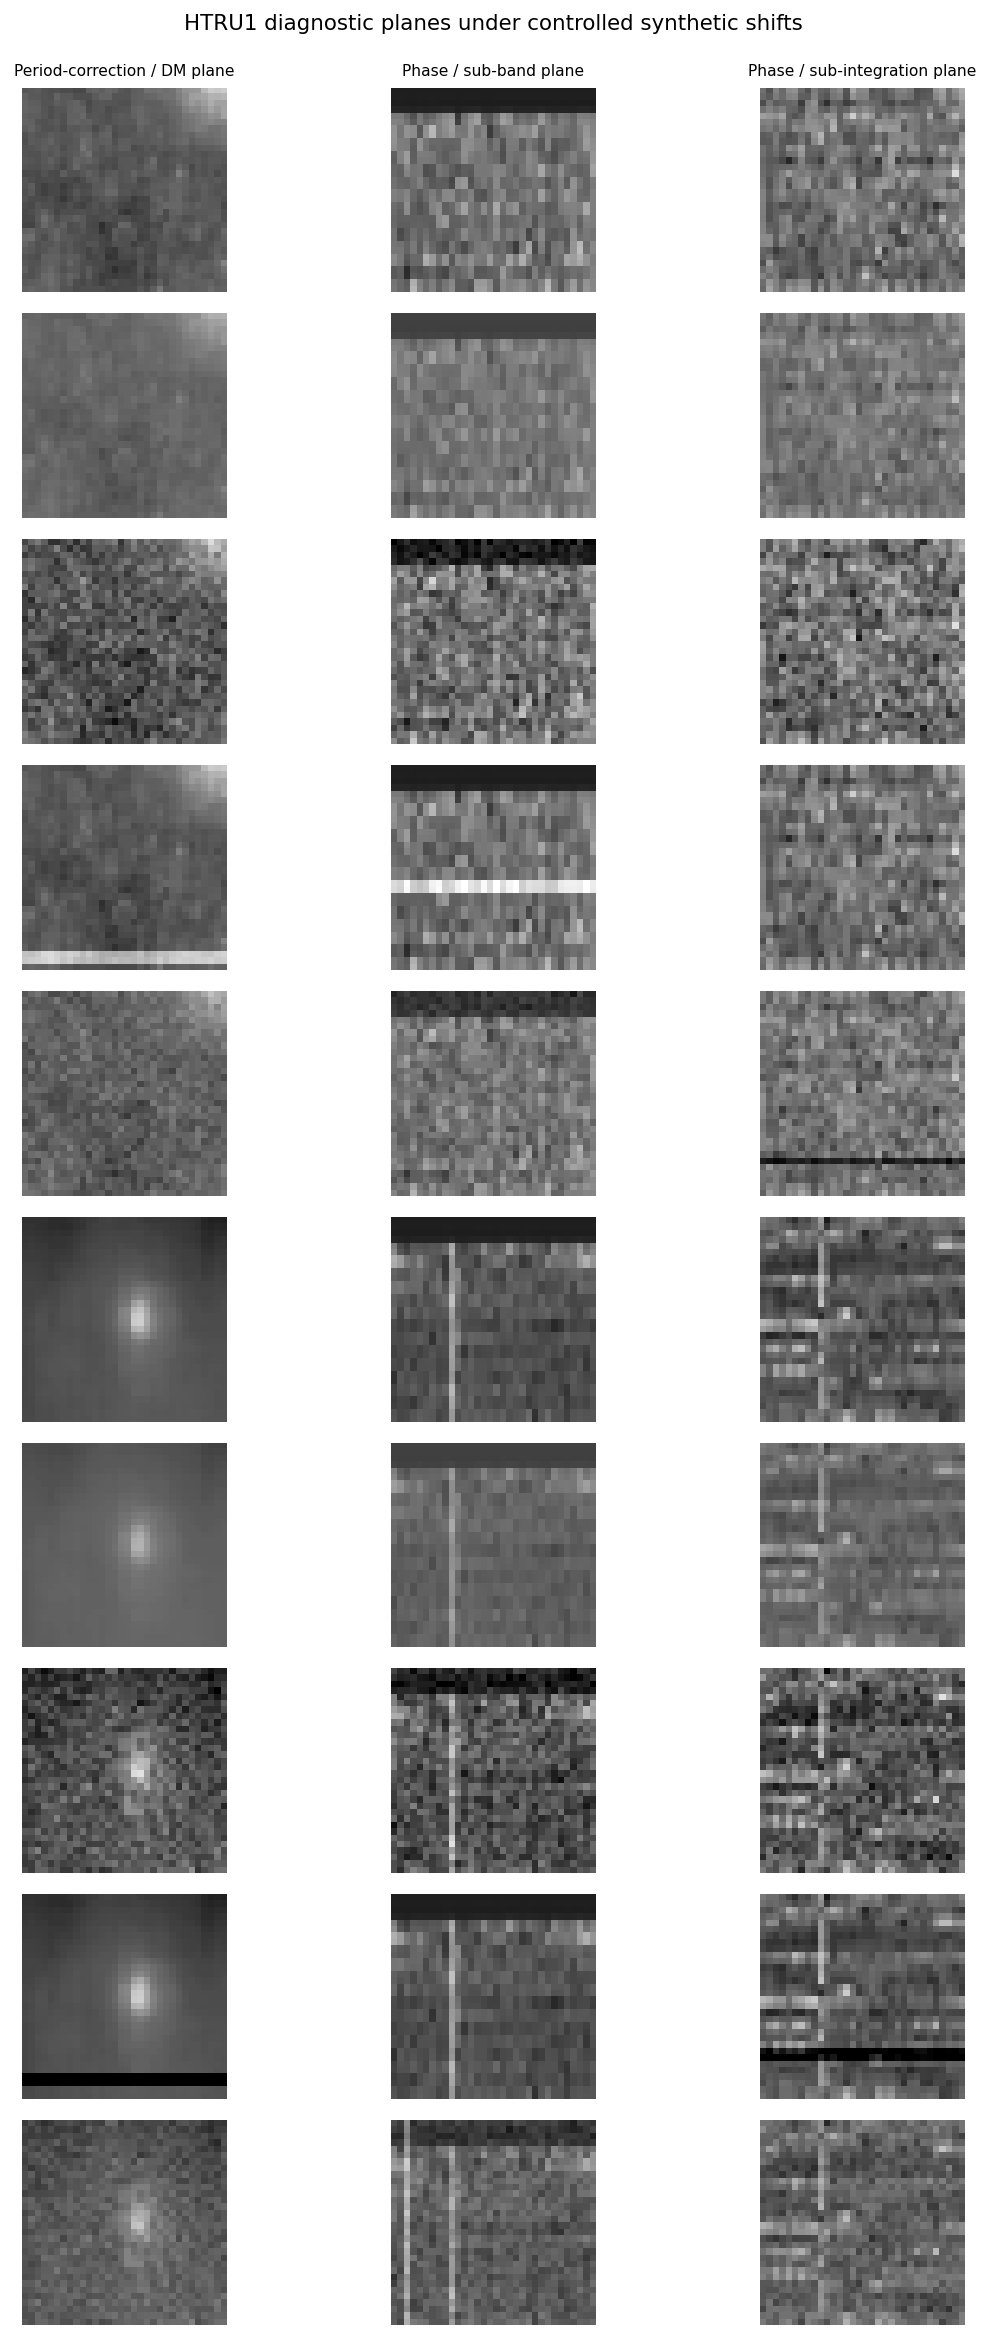

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /content/drive/MyDrive/Pulsar_Experiment_B_Robustness/torch_home/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 79.8MB/s]


Model smoke test PASS: resnet18_clean, logits shape=(2, 2)
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /content/drive/MyDrive/Pulsar_Experiment_B_Robustness/torch_home/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 119MB/s]


Model smoke test PASS: mobilenet_v3_small_clean, logits shape=(2, 2)
Model smoke test PASS: yolo11n_cls_clean, logits shape=(2, 2)

CELL 1 COMPLETE — ALL DATA, CORRUPTION, AND MODEL SMOKE TESTS PASSED.
Review the preview at: /content/drive/MyDrive/Pulsar_Experiment_B_Robustness/reports/experimentB_corruption_preview.png
If any image corruption looks unrealistic, stop here and refine the proxy before training.
No model has been trained. Next, run Cell 2 in the same Colab runtime.


In [ ]:
# CELL 1 — Environment, data verification, corruption preview, and model smoke tests.
# Run this cell first. It will NOT train a model.

import os, sys, json, time, hashlib, pickle, shutil, tarfile, urllib.request, subprocess, warnings
from pathlib import Path
from datetime import datetime, timezone

# Install Ultralytics only if missing. This is needed for the YOLO11n classification benchmark.
try:
    import ultralytics
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])

from google.colab import drive
drive.mount('/content/drive')

# Keep caches and durable study artifacts on Drive; extracted arrays remain in temporary Colab storage.
PROJECT = Path('/content/drive/MyDrive/Pulsar_Experiment_B_Robustness')
RAW_DIR = PROJECT / 'raw'
SPLIT_DIR = PROJECT / 'splits'
MODEL_DIR = PROJECT / 'models'
REPORT_DIR = PROJECT / 'reports'
CACHE_DIR = PROJECT / 'robustness_cache'
TORCH_HOME = PROJECT / 'torch_home'
LOCAL_WORK = Path('/content/pulsar_experiment_b_work')
LOCAL_DATA = LOCAL_WORK / 'dataset'
for p in [RAW_DIR, SPLIT_DIR, MODEL_DIR, REPORT_DIR, CACHE_DIR, TORCH_HOME, LOCAL_WORK]:
    p.mkdir(parents=True, exist_ok=True)
os.environ['TORCH_HOME'] = str(TORCH_HOME)
os.environ['YOLO_CONFIG_DIR'] = str(PROJECT / 'ultralytics_config')
Path(os.environ['YOLO_CONFIG_DIR']).mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPyImage
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.models import resnet18, ResNet18_Weights, mobilenet_v3_small, MobileNet_V3_Small_Weights
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, roc_auc_score, balanced_accuracy_score, precision_score, recall_score
from ultralytics import YOLO

# ------------------------ Fixed experiment configuration ------------------------
DATA_URL = 'https://zenodo.org/records/3205409/files/htru1-batches-py.tar.gz?download=1'
DATA_MD5 = 'e7b063301ada3eb50f212afeea185a36'
ARCHIVE_PATH = RAW_DIR / 'htru1-batches-py.tar.gz'
SPLIT_PATH_OLD = Path('/content/drive/MyDrive/Pulsar_CLAHE_ResNet18_Study/raw/train_val_indices_seed42.npz')
SPLIT_PATH = SPLIT_DIR / 'train_val_indices_seed42.npz'
SEED = 42
IMG_SIZE = 128
BATCH_SIZE = 128
NUM_WORKERS = 2
MAX_EPOCHS = 8
EARLY_STOPPING_PATIENCE = 3
SESSION_BUDGET_MINUTES = 105
TOP_K = 100
BENCHMARK_N = 384
BENCH_BATCH_SIZES = [1, 64]
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type != 'cuda':
    raise RuntimeError('No GPU detected. In Colab select Runtime > Change runtime type > GPU, then rerun Cell 1.')
torch.set_num_threads(2)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

print('=' * 78)
print('EXPERIMENT B — HTRU1 ROBUSTNESS + INFERENCE-THROUGHPUT PREFLIGHT')
print('UTC:', datetime.now(timezone.utc).isoformat())
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__, '| torchvision:', torchvision.__version__, '| Ultralytics:', ultralytics.__version__)
print('Drive output:', PROJECT)
print('Training epochs:', MAX_EPOCHS, '| early-stopping patience:', EARLY_STOPPING_PATIENCE)
print('Models planned: ResNet18-clean, ResNet18-shift-augmented, MobileNetV3-Small, YOLO11n-cls')
print('Official HTRU1 test batch will not be evaluated in this experiment because it was examined in earlier work.')
print('=' * 78)

# ------------------------ Download and verify HTRU1 archive ------------------------
def md5_file(path):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(4 * 1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

# Reuse the verified archive downloaded during the earlier HTRU1 CLAHE study when available.
PRIOR_ARCHIVE_PATH = Path('/content/drive/MyDrive/Pulsar_CLAHE_ResNet18_Study/raw/htru1-batches-py.tar.gz')
if not ARCHIVE_PATH.exists() and PRIOR_ARCHIVE_PATH.exists():
    prior_md5 = md5_file(PRIOR_ARCHIVE_PATH)
    if prior_md5 == DATA_MD5:
        ARCHIVE_PATH = PRIOR_ARCHIVE_PATH
        print('Reusing prior verified HTRU1 archive on Drive; no second archive download needed.')
    else:
        print('Prior study archive failed MD5; will download a fresh verified archive.')

if ARCHIVE_PATH.exists():
    existing_md5 = md5_file(ARCHIVE_PATH)
    if existing_md5 != DATA_MD5:
        raise RuntimeError(f'Existing HTRU1 archive failed MD5 verification: {existing_md5}. File retained for inspection: {ARCHIVE_PATH}')
    print('HTRU1 archive already exists on Drive; MD5 PASS.')
else:
    part = ARCHIVE_PATH.with_suffix('.tar.gz.part')
    if part.exists():
        part.unlink()  # This archive is only ~183 MB; restart partial download cleanly.
    print('Downloading official HTRU1 archive to Drive...')
    request = urllib.request.Request(DATA_URL, headers={'User-Agent': 'Mozilla/5.0 HTRU1-Experiment-B'})
    with urllib.request.urlopen(request, timeout=90) as response, open(part, 'wb') as f:
        expected = response.headers.get('Content-Length')
        total = 0
        while True:
            block = response.read(4 * 1024 * 1024)
            if not block:
                break
            f.write(block)
            total += len(block)
            if total and total % (32 * 1024 * 1024) < len(block):
                print(f'  Downloaded {total / 1e6:.0f} MB')
        f.flush()
        os.fsync(f.fileno())
    got = md5_file(part)
    if got != DATA_MD5:
        part.unlink(missing_ok=True)
        raise RuntimeError(f'HTRU1 MD5 mismatch. Expected {DATA_MD5}, received {got}.')
    os.replace(part, ARCHIVE_PATH)
    print('Archive downloaded and MD5 verified:', got)

# ------------------------ Safe extraction and HTRU1 loading ------------------------
def load_pickle(path):
    with open(path, 'rb') as f:
        return pickle.load(f, encoding='bytes')

def field(obj, name):
    return obj.get(name.encode(), obj.get(name))

def decode_text(x):
    return x.decode('utf-8') if isinstance(x, (bytes, bytearray)) else str(x)

metas = list(LOCAL_DATA.rglob('batches.meta')) if LOCAL_DATA.exists() else []
if metas and all((metas[0].parent / f'data_batch_{i}').exists() for i in range(1, 6)) and (metas[0].parent / 'test_batch').exists():
    DATA_DIR = metas[0].parent
else:
    if LOCAL_DATA.exists():
        shutil.rmtree(LOCAL_DATA)
    LOCAL_DATA.mkdir(parents=True, exist_ok=True)
    print('Extracting verified HTRU1 archive into temporary Colab storage...')
    with tarfile.open(ARCHIVE_PATH, 'r:gz') as tf:
        try:
            tf.extractall(path=LOCAL_DATA, filter='data')
        except TypeError:  # Compatibility with Python versions without tar extraction filters.
            tf.extractall(path=LOCAL_DATA)
    metas = list(LOCAL_DATA.rglob('batches.meta'))
    if not metas:
        raise FileNotFoundError('batches.meta missing after extracting verified archive.')
    DATA_DIR = metas[0].parent

meta = load_pickle(DATA_DIR / 'batches.meta')
class_names = [decode_text(v).lower() for v in field(meta, 'label_names')]
pulsar_ids = [i for i, n in enumerate(class_names) if 'pulsar' in n and 'non' not in n]
if len(pulsar_ids) != 1:
    raise ValueError(f'Could not uniquely identify pulsar class in labels: {class_names}')
pulsar_id = pulsar_ids[0]

train_flat, train_labels = [], []
for b in range(1, 6):
    batch = load_pickle(DATA_DIR / f'data_batch_{b}')
    train_flat.append(np.asarray(field(batch, 'data'), dtype=np.uint8))
    train_labels.append(np.asarray(field(batch, 'labels'), dtype=np.int64))
test_obj = load_pickle(DATA_DIR / 'test_batch')
test_flat = np.asarray(field(test_obj, 'data'), dtype=np.uint8)
test_labels_raw = np.asarray(field(test_obj, 'labels'), dtype=np.int64)

X_train_raw = np.concatenate(train_flat, axis=0).reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1).copy()
y_train = (np.concatenate(train_labels) == pulsar_id).astype(np.int64)  # 0=non-pulsar, 1=pulsar
X_test_raw = test_flat.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1).copy()
y_test = (test_labels_raw == pulsar_id).astype(np.int64)

assert X_train_raw.shape == (50000, 32, 32, 3), X_train_raw.shape
assert X_test_raw.shape == (10000, 32, 32, 3), X_test_raw.shape
assert int(y_train.sum()) == 995, int(y_train.sum())
assert int(y_test.sum()) == 199, int(y_test.sum())
assert X_train_raw.dtype == np.uint8 and X_test_raw.dtype == np.uint8
assert np.isfinite(X_train_raw).all() and np.isfinite(X_test_raw).all()
print('\nHTRU1 data integrity: PASS')
print('Class names in archive:', class_names, '| positive label used by experiment: pulsar=1')
print(f'Training batch: {X_train_raw.shape}; pulsars={y_train.sum():,}; non-pulsars={(y_train == 0).sum():,}')
print(f'Official test batch integrity only: {X_test_raw.shape}; pulsars={y_test.sum():,}; not used for Experiment B evaluation')

# Reuse the exact train/validation split from the earlier HTRU1 study if available.
if SPLIT_PATH_OLD.exists():
    split_obj = np.load(SPLIT_PATH_OLD)
    tr_idx, va_idx = split_obj['train_idx'], split_obj['val_idx']
    if len(tr_idx) != 42500 or len(va_idx) != 7500 or set(tr_idx) & set(va_idx):
        raise ValueError('Previously saved HTRU1 split exists but failed shape/disjointness checks.')
    source_split = str(SPLIT_PATH_OLD)
else:
    tr_idx, va_idx = train_test_split(
        np.arange(len(y_train)), test_size=0.15, random_state=SEED, stratify=y_train
    )
    source_split = 'new stratified 85/15 split, seed 42'
np.savez(SPLIT_PATH, train_idx=tr_idx, val_idx=va_idx)
X_val_raw = X_train_raw[va_idx]
y_val = y_train[va_idx].copy()
y_tr = y_train[tr_idx]
assert set(np.unique(y_val)) == {0, 1}
print('Split source:', source_split)
print(f'Fixed split: train={len(tr_idx):,} (pulsars={y_tr.sum():,}), validation={len(va_idx):,} (pulsars={y_val.sum():,})')

# ------------------------ Controlled image-space stress conditions ------------------------
# These are engineering proxies for image-domain shifts, NOT physically calibrated telescope/RFI simulations.
CORRUPTIONS = [
    'clean', 'contrast_low', 'contrast_high', 'gaussian_noise_mild',
    'gaussian_noise_strong', 'rfi_stripes_mild', 'rfi_stripes_strong', 'combined_stress'
]

def corrupt_images(images, condition, seed=1234):
    images = np.asarray(images, dtype=np.uint8)
    if condition == 'clean':
        return images.copy()
    rng = np.random.default_rng(seed)
    x = images.astype(np.float32)
    if condition == 'contrast_low':
        x = (x - 127.5) * 0.65 + 127.5
    elif condition == 'contrast_high':
        x = (x - 127.5) * 1.35 + 127.5
    elif condition == 'gaussian_noise_mild':
        x = x + rng.normal(0, 8.0, size=x.shape).astype(np.float32)
    elif condition == 'gaussian_noise_strong':
        x = x + rng.normal(0, 18.0, size=x.shape).astype(np.float32)
    elif condition in ('rfi_stripes_mild', 'rfi_stripes_strong', 'combined_stress'):
        if condition == 'combined_stress':
            x = (x - 127.5) * 0.75 + 127.5
            x = x + rng.normal(0, 10.0, size=x.shape).astype(np.float32)
            n_lines, width, strength = 1, 1, 75.0
        elif condition == 'rfi_stripes_mild':
            n_lines, width, strength = 1, 1, 65.0
        else:
            n_lines, width, strength = 2, 2, 110.0
        # Insert narrow artificial bright/dark bands in one selected diagnostic plane per line.
        N, H, W, C = x.shape
        for i in range(N):
            for _ in range(n_lines):
                c = int(rng.integers(0, C))
                sign = 1.0 if rng.random() < 0.75 else -1.0
                if rng.random() < 0.5:
                    pos = int(rng.integers(0, W - width + 1))
                    x[i, :, pos:pos + width, c] += sign * strength
                else:
                    pos = int(rng.integers(0, H - width + 1))
                    x[i, pos:pos + width, :, c] += sign * strength
    else:
        raise KeyError(f'Unknown corruption: {condition}')
    return np.clip(x, 0, 255).astype(np.uint8)

# Normalization is consistent across all PyTorch models and all conditions.
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], dtype=torch.float32).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], dtype=torch.float32).view(1, 3, 1, 1)

def apply_random_shift_augmentation(x):
    """Batch-wise synthetic robustness augmentation for ResNet18-shiftaug; x is float [0,1], NCHW at native 32x32."""
    B, C, H, W = x.shape
    mode = torch.randint(0, 5, (B,), device=x.device)  # 0=identity, 1=contrast, 2=noise, 3=stripes, 4=combined
    contrast = torch.empty((B, 1, 1, 1), device=x.device).uniform_(0.65, 1.35)
    x_contrast = ((x - 0.5) * contrast + 0.5).clamp(0, 1)
    use_contrast = ((mode == 1) | (mode == 4)).view(B, 1, 1, 1)
    x = torch.where(use_contrast, x_contrast, x)
    sigma = torch.empty((B, 1, 1, 1), device=x.device).uniform_(0.025, 0.075)
    noise = torch.randn_like(x) * sigma
    use_noise = ((mode == 2) | (mode == 4)).view(B, 1, 1, 1)
    x = torch.where(use_noise, (x + noise).clamp(0, 1), x)
    use_stripe = ((mode == 3) | (mode == 4))
    if use_stripe.any():
        channels = torch.randint(0, C, (B,), device=x.device)
        hpos = torch.randint(0, H, (B,), device=x.device)
        wpos = torch.randint(0, W, (B,), device=x.device)
        rows = torch.arange(H, device=x.device).view(1, 1, H, 1)
        cols = torch.arange(W, device=x.device).view(1, 1, 1, W)
        one_hot_channel = F.one_hot(channels, num_classes=C).float().view(B, C, 1, 1)
        stripe_mask = ((rows == hpos.view(B, 1, 1, 1)) | (cols == wpos.view(B, 1, 1, 1))).float()
        stripe_mask = stripe_mask * one_hot_channel * use_stripe.float().view(B, 1, 1, 1)
        sign = torch.where(torch.rand((B, 1, 1, 1), device=x.device) < 0.75, 1.0, -1.0)
        x = (x + stripe_mask * sign * 0.30).clamp(0, 1)
    return x

def prepare_batch(raw_chw, device, shift_augment=False):
    # raw_chw: uint8 tensor [B,3,32,32]. Preprocessing is shared across all conditions/models.
    x = raw_chw.to(device=device, non_blocking=True).float().div_(255.0)
    if shift_augment:
        x = apply_random_shift_augmentation(x)
    x = F.interpolate(x, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)
    mean = IMAGENET_MEAN.to(device)
    std = IMAGENET_STD.to(device)
    return (x - mean) / std

# ------------------------ Model construction ------------------------
def build_model(model_name):
    if model_name in ('resnet18_clean', 'resnet18_shiftaug'):
        model = resnet18(weights=ResNet18_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, 2)
    elif model_name == 'mobilenet_v3_small_clean':
        model = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT)
        model.classifier[3] = nn.Linear(model.classifier[3].in_features, 2)
    elif model_name == 'yolo11n_cls_clean':
        wrapper = YOLO('yolo11n-cls.pt')  # classification model, not an OBB detector
        model = wrapper.model
        head = model.model[-1]
        if not hasattr(head, 'linear'):
            raise RuntimeError('Expected Ultralytics YOLO classification head with a linear layer.')
        head.linear = nn.Linear(head.linear.in_features, 2)
        if hasattr(model, 'nc'):
            model.nc = 2
        if hasattr(model, 'names'):
            model.names = {0: 'nonpulsar', 1: 'pulsar'}
        if hasattr(model, 'yaml') and isinstance(model.yaml, dict):
            model.yaml['nc'] = 2
    else:
        raise KeyError(f'Unknown model name: {model_name}')
    return model

# ------------------------ Smoke-test corruptions and all model architectures ------------------------
# Ensure image perturbations are valid, reproducible, and change the sample pixels.
smoke_n = min(64, len(X_val_raw))
smoke_images = X_val_raw[:smoke_n]
corruption_smoke = {}
for condition in CORRUPTIONS:
    transformed = corrupt_images(smoke_images, condition, seed=2026)
    assert transformed.shape == smoke_images.shape and transformed.dtype == np.uint8
    assert np.isfinite(transformed).all()
    changed_fraction = float(np.mean(transformed != smoke_images))
    corruption_smoke[condition] = changed_fraction
    if condition != 'clean' and not np.any(transformed != smoke_images):
        raise RuntimeError(f'Corruption {condition} did not alter the smoke-test images.')
    print(f'Corruption smoke test: {condition:24s} changed-pixel fraction={changed_fraction:.4%}')

# Save and display channel-by-channel previews for one pulsar and one non-pulsar.
# HTRU1's 3 channels are separate diagnostic planes, not literal RGB colour bands.
pos_i = int(np.flatnonzero(y_val == 1)[0])
neg_i = int(np.flatnonzero(y_val == 0)[0])
preview_indices = [neg_i, pos_i]
preview_conditions = ['clean', 'contrast_low', 'gaussian_noise_strong', 'rfi_stripes_strong', 'combined_stress']
channel_titles = ['Period-correction / DM plane', 'Phase / sub-band plane', 'Phase / sub-integration plane']
fig, axes = plt.subplots(len(preview_indices) * len(preview_conditions), 3, figsize=(9, 17))
plot_row = 0
for local_i in preview_indices:
    source = X_val_raw[local_i:local_i + 1]
    cls_name = 'PULSAR' if y_val[local_i] == 1 else 'NON-PULSAR'
    for condition in preview_conditions:
        img = corrupt_images(source, condition, seed=101 + local_i)[0]
        for channel in range(3):
            axes[plot_row, channel].imshow(img[:, :, channel], cmap='gray', vmin=0, vmax=255)
            axes[plot_row, channel].axis('off')
            if plot_row == 0:
                axes[plot_row, channel].set_title(channel_titles[channel], fontsize=8)
        axes[plot_row, 0].set_ylabel(f'{cls_name} | {condition}', fontsize=8)
        plot_row += 1
fig.suptitle('HTRU1 diagnostic planes under controlled synthetic shifts', fontsize=11)
fig.tight_layout(rect=[0, 0, 1, 0.985])
PREVIEW_PATH = REPORT_DIR / 'experimentB_corruption_preview.png'
fig.savefig(PREVIEW_PATH, dpi=140, bbox_inches='tight')
plt.close(fig)
print('Saved corruption preview:', PREVIEW_PATH)
display(IPyImage(filename=str(PREVIEW_PATH)))

# Ensure all model heads produce exactly two class logits on the same preprocessed sample.
smoke_raw = torch.from_numpy(np.ascontiguousarray(smoke_images[:2].transpose(0, 3, 1, 2)))
smoke_tensor = prepare_batch(smoke_raw, DEVICE, shift_augment=False)
model_smoke = {}
for model_name in ['resnet18_clean', 'mobilenet_v3_small_clean', 'yolo11n_cls_clean']:
    model = build_model(model_name).to(DEVICE).eval()
    with torch.inference_mode():
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=True):
            output = model(smoke_tensor)
    if isinstance(output, (list, tuple)):
        output = output[1] if len(output) > 1 and torch.is_tensor(output[1]) else output[0]
    assert torch.is_tensor(output) and tuple(output.shape) == (2, 2), (model_name, type(output), getattr(output, 'shape', None))
    model_smoke[model_name] = {'output_shape': list(output.shape), 'finite_logits': bool(torch.isfinite(output.float()).all().item())}
    assert model_smoke[model_name]['finite_logits']
    print(f'Model smoke test PASS: {model_name}, logits shape={tuple(output.shape)}')
    del model, output
    torch.cuda.empty_cache()

# Save preflight state; Cell 2 uses the arrays and functions currently in memory.
verification = {
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'dataset': 'HTRU1 Batched Dataset, Zenodo record 3205409',
    'archive_path': str(ARCHIVE_PATH),
    'archive_md5': md5_file(ARCHIVE_PATH),
    'train_shape': list(X_train_raw.shape),
    'test_shape_integrity_only': list(X_test_raw.shape),
    'train_positive': int(y_train.sum()),
    'train_negative': int((y_train == 0).sum()),
    'validation_count': int(len(y_val)),
    'validation_positive': int(y_val.sum()),
    'validation_negative': int((y_val == 0).sum()),
    'split_source': source_split,
    'seed': SEED,
    'gpu': torch.cuda.get_device_name(0),
    'corruption_pixel_change_smoke': corruption_smoke,
    'model_smoke_tests': model_smoke,
    'preview_path': str(PREVIEW_PATH),
    'official_test_not_used': True,
    'important_limit': 'Image-space corruptions are synthetic robustness proxies, not a calibrated or time-separated MeerKAT RFI benchmark.'
}
(REPORT_DIR / 'cell1_preflight.json').write_text(json.dumps(verification, indent=2))
print('\n' + '=' * 78)
print('CELL 1 COMPLETE — ALL DATA, CORRUPTION, AND MODEL SMOKE TESTS PASSED.')
print('Review the preview at:', PREVIEW_PATH)
print('If any image corruption looks unrealistic, stop here and refine the proxy before training.')
print('No model has been trained. Next, run Cell 2 in the same Colab runtime.')
print('=' * 78)


In [ ]:
from pathlib import Path
import numpy as np

p = Path(
    "/content/drive/MyDrive/Pulsar_CLAHE_ResNet18_Study/"
    "raw/train_val_indices_seed42.npz"
)

print("Previous split exists:", p.exists())

if p.exists():
    split = np.load(p)
    print("Train indices:", len(split["train_idx"]))
    print("Validation indices:", len(split["val_idx"]))

Previous split exists: False


In [ ]:
# CELL 2 — Train once per model, evaluate controlled robustness, and benchmark inference speed.
# Run only after Cell 1 passes. This cell saves all durable results/checkpoints to Drive.

import os, sys, json, time, math, random, shutil, traceback
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import average_precision_score, roc_auc_score, balanced_accuracy_score, precision_score, recall_score

if 'X_train_raw' not in globals() or 'corrupt_images' not in globals() or 'build_model' not in globals():
    raise RuntimeError('Cell 1 state is missing. Run Cell 1 successfully in this runtime, then rerun Cell 2.')
if not torch.cuda.is_available():
    raise RuntimeError('GPU not detected. Reconnect a GPU runtime before running Cell 2.')

# One fixed seed only. No multi-seed replication. The held-out validation split is reused for robustness analysis.
set_seed = 42
max_epochs = 8
early_patience = 3
session_budget_minutes = 105
batch_size = 128
num_workers = 2
top_k = 100
benchmark_n = min(384, len(X_val_raw))
bench_batch_sizes = [1, 64]
DEVICE = torch.device('cuda')
SESSION_START = time.monotonic()
SESSION_DEADLINE = SESSION_START + session_budget_minutes * 60

MODEL_NAMES = [
    'resnet18_clean',
    'resnet18_shiftaug',
    'mobilenet_v3_small_clean',
    'yolo11n_cls_clean',
]
MODEL_DIR = PROJECT / 'models'
REPORT_DIR = PROJECT / 'reports'
CACHE_DIR = PROJECT / 'robustness_cache'
for p in [MODEL_DIR, REPORT_DIR, CACHE_DIR]:
    p.mkdir(parents=True, exist_ok=True)


def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def atomic_torch_save(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    local_tmp = Path('/content') / (path.name + '.tmp')
    torch.save(obj, local_tmp)
    drive_tmp = path.with_name(path.name + '.tmp')
    shutil.copy2(local_tmp, drive_tmp)
    os.replace(drive_tmp, path)
    local_tmp.unlink(missing_ok=True)


def atomic_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2, default=str))
    os.replace(tmp, path)


def output_logits(model, x):
    out = model(x)
    if isinstance(out, (tuple, list)):
        tensor_outputs = [z for z in out if torch.is_tensor(z) and z.ndim == 2]
        if not tensor_outputs:
            raise RuntimeError(f'Model returned unsupported output type: {type(out)}')
        out = tensor_outputs[-1]
    if out.ndim != 2 or out.shape[1] != 2:
        raise RuntimeError(f'Expected [batch,2] class logits, received {tuple(out.shape)}')
    return out


class HTRUIndexedDataset(Dataset):
    def __init__(self, images, labels, indices):
        self.images = images
        self.labels = labels
        self.indices = np.asarray(indices, dtype=np.int64)
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, ix):
        source_index = int(self.indices[ix])
        image = self.images[source_index]
        chw = np.ascontiguousarray(image.transpose(2, 0, 1))
        return torch.from_numpy(chw), torch.tensor(int(self.labels[source_index]), dtype=torch.long)


def compute_metrics(y_true, probs, k=top_k):
    y_true = np.asarray(y_true, dtype=np.int32)
    probs = np.asarray(probs, dtype=np.float64)
    pred = (probs >= 0.5).astype(np.int32)
    order = np.argsort(probs)[::-1]
    k_eff = min(int(k), len(order))
    top_positive = int(y_true[order[:k_eff]].sum())
    return {
        'AP': float(average_precision_score(y_true, probs)),
        'ROC_AUC': float(roc_auc_score(y_true, probs)),
        'balanced_accuracy_at_0.5': float(balanced_accuracy_score(y_true, pred)),
        'precision_at_0.5': float(precision_score(y_true, pred, zero_division=0)),
        'recall_at_0.5': float(recall_score(y_true, pred, zero_division=0)),
        'top_k': int(k_eff),
        'top_k_true_pulsars': top_positive,
        'precision_at_top_k': float(top_positive / k_eff) if k_eff else 0.0,
        'recall_at_top_k': float(top_positive / max(int(y_true.sum()), 1)),
        'positive_prevalence': float(y_true.mean()),
        'false_positives_at_0.5': int(np.sum((y_true == 0) & (pred == 1))),
        'false_negatives_at_0.5': int(np.sum((y_true == 1) & (pred == 0))),
    }


def evaluate_model(model, images, labels, device=DEVICE, batch=128, use_amp=True):
    model.eval()
    dataset = HTRUIndexedDataset(images, labels, np.arange(len(labels)))
    loader = DataLoader(dataset, batch_size=batch, shuffle=False, num_workers=num_workers,
                        pin_memory=(device.type == 'cuda'), persistent_workers=(num_workers > 0))
    scores = []
    with torch.inference_mode():
        for raw, _labels in loader:
            x = prepare_batch(raw, device, shift_augment=False)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(device.type == 'cuda' and use_amp)):
                logits = output_logits(model, x)
            probs = torch.softmax(logits.float(), dim=1)[:, 1]
            scores.extend(probs.detach().cpu().numpy().tolist())
    del loader, dataset
    return np.asarray(scores, dtype=np.float64)


def save_epoch_log(path, row):
    path = Path(path)
    exists = path.exists()
    with open(path, 'a', newline='', encoding='utf-8') as f:
        pd.DataFrame([row]).to_csv(f, header=not exists, index=False)
        f.flush()
        os.fsync(f.fileno())


def train_one_model(model_name):
    run_dir = MODEL_DIR / model_name
    run_dir.mkdir(parents=True, exist_ok=True)
    best_path = run_dir / 'best.pt'
    last_path = run_dir / 'last.pt'
    completed_path = run_dir / 'completed.json'
    epoch_csv = run_dir / 'epoch_metrics.csv'

    if completed_path.exists() and best_path.exists():
        result = json.loads(completed_path.read_text())
        print(f'Already completed: {model_name} (best val AP={result["best_val_AP"]:.4f}); skipping training.')
        return result

    set_all_seeds(set_seed)
    model = build_model(model_name).to(DEVICE)
    counts = np.bincount(y_tr, minlength=2).astype(np.float32)
    class_weights = len(y_tr) / (2.0 * counts)
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=DEVICE))
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=5e-4)
    scaler = torch.amp.GradScaler('cuda', enabled=True)
    generator = torch.Generator().manual_seed(set_seed + 900)
    train_ds = HTRUIndexedDataset(X_train_raw, y_train, tr_idx)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=num_workers,
                              pin_memory=True, generator=generator, persistent_workers=(num_workers > 0))

    start_epoch, best_ap, best_epoch, no_improve, resumed = 1, -1.0, 0, 0, False
    if last_path.exists():
        ckpt = torch.load(last_path, map_location='cpu', weights_only=False)
        model.load_state_dict(ckpt['model_state_dict'])
        optimizer.load_state_dict(ckpt['optimizer_state_dict'])
        scaler.load_state_dict(ckpt['scaler_state_dict'])
        start_epoch = int(ckpt['epoch']) + 1
        best_ap = float(ckpt.get('best_val_AP', -1.0))
        best_epoch = int(ckpt.get('best_epoch', 0))
        no_improve = int(ckpt.get('no_improve', 0))
        if ckpt.get('loader_generator_state') is not None:
            generator.set_state(ckpt['loader_generator_state'])
        if ckpt.get('rng_torch') is not None:
            torch.set_rng_state(ckpt['rng_torch'].cpu())
        if ckpt.get('rng_cuda') is not None:
            torch.cuda.set_rng_state_all([s.cpu() for s in ckpt['rng_cuda']])
        if ckpt.get('rng_numpy') is not None:
            np.random.set_state(ckpt['rng_numpy'])
        if ckpt.get('rng_python') is not None:
            random.setstate(ckpt['rng_python'])
        resumed = True
        print(f'Resuming {model_name} from epoch {start_epoch}.')

    use_shift_aug = model_name == 'resnet18_shiftaug'
    print(f'\n=== Training {model_name} | pretrained backbone | class-weighted loss | seed={set_seed} ===')
    history = []
    for epoch in range(start_epoch, max_epochs + 1):
        if time.monotonic() >= SESSION_DEADLINE:
            print('Session budget reached. Checkpoints are saved; rerun Cell 2 to resume.')
            del model, optimizer, scaler, train_loader
            torch.cuda.empty_cache()
            return {'model': model_name, 'status': 'paused', 'last_epoch': epoch - 1}

        model.train()
        loss_sum, seen = 0.0, 0
        for raw, labels in train_loader:
            x = prepare_batch(raw, DEVICE, shift_augment=use_shift_aug)
            labels = labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=True):
                logits = output_logits(model, x)
                loss = criterion(logits, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            loss_sum += float(loss.detach().item()) * len(labels)
            seen += len(labels)

        train_loss = loss_sum / max(seen, 1)
        y_val_local = y_train[va_idx]
        val_scores = evaluate_model(model, X_train_raw[va_idx], y_val_local, batch=batch_size)
        val_metrics = compute_metrics(y_val_local, val_scores)
        row = {
            'model': model_name, 'seed': set_seed, 'epoch': epoch,
            'train_loss': train_loss, 'val_AP': val_metrics['AP'], 'val_ROC_AUC': val_metrics['ROC_AUC'],
            'val_precision_at_top100': val_metrics['precision_at_top_k'],
            'val_recall_at_top100': val_metrics['recall_at_top_k'],
            'timestamp_utc': datetime.now(timezone.utc).isoformat(),
        }
        save_epoch_log(epoch_csv, row)
        history.append(row)
        print(f'Epoch {epoch:02d}/{max_epochs} | loss={train_loss:.5f} | val AP={val_metrics["AP"]:.4f} | '
              f'val AUC={val_metrics["ROC_AUC"]:.4f} | P@100={val_metrics["precision_at_top_k"]:.3f}')

        improved = val_metrics['AP'] > best_ap + 1e-6
        if improved:
            best_ap = val_metrics['AP']
            best_epoch = epoch
            no_improve = 0
            atomic_torch_save({
                'model_name': model_name, 'seed': set_seed, 'epoch': epoch,
                'model_state_dict': {k: v.detach().cpu() for k, v in model.state_dict().items()},
                'best_val_AP': best_ap, 'best_val_metrics': val_metrics,
                'class_weights': class_weights.tolist(), 'image_size': IMG_SIZE,
                'label_mapping': {'0': 'non-pulsar', '1': 'pulsar'},
            }, best_path)
            print('  Best AP checkpoint saved.')
        else:
            no_improve += 1

        last_payload = {
            'model_name': model_name, 'epoch': epoch,
            'model_state_dict': model.state_dict(), 'optimizer_state_dict': optimizer.state_dict(),
            'scaler_state_dict': scaler.state_dict(), 'best_val_AP': best_ap,
            'best_epoch': best_epoch, 'no_improve': no_improve,
            'class_weights': class_weights.tolist(), 'loader_generator_state': generator.get_state(),
            'rng_torch': torch.get_rng_state(), 'rng_cuda': torch.cuda.get_rng_state_all(),
            'rng_numpy': np.random.get_state(), 'rng_python': random.getstate(),
        }
        atomic_torch_save(last_payload, last_path)
        atomic_json(REPORT_DIR / 'latest_progress.json', {
            'status': 'training', 'active_model': model_name, 'completed_epoch': epoch,
            'best_validation_AP': best_ap, 'updated_utc': datetime.now(timezone.utc).isoformat()
        })

        if no_improve >= early_patience:
            print(f'Early stopping at epoch {epoch}; best AP was epoch {best_epoch}.')
            break

    if not best_path.exists():
        raise RuntimeError(f'No best checkpoint exists for {model_name}.')
    best_ckpt = torch.load(best_path, map_location='cpu', weights_only=False)
    result = {
        'model': model_name, 'status': 'completed', 'seed': set_seed,
        'best_epoch': int(best_ckpt['epoch']), 'best_val_AP': float(best_ckpt['best_val_AP']),
        'best_val_metrics': best_ckpt['best_val_metrics'], 'best_checkpoint': str(best_path),
        'epochs_logged_this_session': len(history), 'resumed': resumed,
        'max_epochs': max_epochs, 'early_stopping_patience': early_patience,
        'training_augmentation': 'controlled random contrast/noise/stripe proxy' if use_shift_aug else 'none (clean training)',
    }
    atomic_json(completed_path, result)
    print(f'Completed {model_name}: best validation AP={result["best_val_AP"]:.4f} at epoch {result["best_epoch"]}.')
    del model, optimizer, scaler, train_loader, train_ds
    torch.cuda.empty_cache()
    return result


def load_best_model(model_name, device=DEVICE):
    model = build_model(model_name)
    checkpoint = torch.load(MODEL_DIR / model_name / 'best.pt', map_location='cpu', weights_only=False)
    model.load_state_dict(checkpoint['model_state_dict'])
    return model.to(device).eval(), checkpoint

# ------------------------ Phase A: train/resume model set ------------------------
print('=' * 78)
print('PHASE A — TRAINING (single fixed seed; no seed replication)')
print('Models: ResNet18-clean, ResNet18-shiftaug, MobileNetV3-Small, YOLO11n-cls')
print('=' * 78)

training_results = []
for name in MODEL_NAMES:
    result = train_one_model(name)
    training_results.append(result)
    atomic_json(REPORT_DIR / 'training_progress.json', {
        'updated_utc': datetime.now(timezone.utc).isoformat(),
        'results': training_results,
    })
    if result.get('status') == 'paused':
        print('Training paused safely. Rerun Cell 2 to resume from Drive checkpoints.')
        raise SystemExit('Experiment B paused at an epoch boundary; no completed work was discarded.')

pd.DataFrame([
    {'model': r['model'], 'best_epoch': r['best_epoch'], 'best_val_AP': r['best_val_AP'],
     'best_val_ROC_AUC': r['best_val_metrics']['ROC_AUC'],
     'P@100': r['best_val_metrics']['precision_at_top_k'],
     'R@100': r['best_val_metrics']['recall_at_top_k']}
    for r in training_results if r.get('status') == 'completed'
]).to_csv(REPORT_DIR / 'model_training_summary.csv', index=False)

# ------------------------ Phase B: robustness evaluations ------------------------
print('\n' + '=' * 78)
print('PHASE B — ROBUSTNESS EVALUATION ON FIXED VALIDATION CANDIDATES')
print('=' * 78)
robust_rows = []
clean_scores_by_model = {}
robust_progress_path = REPORT_DIR / 'robustness_progress.csv'
if robust_progress_path.exists():
    _prior = pd.read_csv(robust_progress_path)
    robust_rows = _prior.to_dict('records')
else:
    _prior = pd.DataFrame()
prior_keys = {(str(r['model']), str(r['condition'])) for r in robust_rows}

for model_name in MODEL_NAMES:
    # Reuse prior clean scores when this cell is rerun after an interruption.
    clean_score_file = REPORT_DIR / f'validation_clean_scores_{model_name}.npz'
    if clean_score_file.exists():
        _cs = np.load(clean_score_file)
        clean_scores_by_model[model_name] = _cs['y_score'].copy()
    model, ckpt = load_best_model(model_name, DEVICE)
    clean_scores = clean_scores_by_model.get(model_name)
    for condition in CORRUPTIONS:
        if (model_name, condition) in prior_keys:
            print(f'Skipping saved robustness result: {model_name} / {condition}')
            continue
        cache_path = CACHE_DIR / f'val_{condition}_seed2026.npy'
        if condition == 'clean':
            images_condition = X_val_raw
        else:
            if cache_path.exists():
                images_condition = np.load(cache_path, mmap_mode='r', allow_pickle=False)
                if images_condition.shape != X_val_raw.shape:
                    cache_path.unlink(missing_ok=True)
                    images_condition = corrupt_images(X_val_raw, condition, seed=2026)
                    np.save(cache_path, images_condition, allow_pickle=False)
            else:
                images_condition = corrupt_images(X_val_raw, condition, seed=2026)
                np.save(cache_path, images_condition, allow_pickle=False)
        scores = evaluate_model(model, images_condition, y_val, batch=batch_size)
        metrics = compute_metrics(y_val, scores)
        if condition == 'clean':
            clean_scores = scores.copy()
            clean_scores_by_model[model_name] = scores.copy()
            np.savez_compressed(clean_score_file, y_true=y_val, y_score=scores)
        score_output = REPORT_DIR / f'validation_scores_{model_name}_{condition}.npz'
        np.savez_compressed(score_output, y_true=y_val, y_score=scores)
        clean_ap = compute_metrics(y_val, clean_scores)['AP'] if clean_scores is not None else float('nan')
        _row = {
            'model': model_name, 'condition': condition,
            **metrics,
            'AP_absolute_delta_vs_clean': float(metrics['AP'] - clean_ap),
            'AP_relative_change_pct_vs_clean': float(100.0 * (metrics['AP'] - clean_ap) / max(clean_ap, 1e-9)),
            'evaluation_examples': len(y_val), 'seed': set_seed, 'score_file': str(score_output),
        }
        robust_rows.append(_row)
        prior_keys.add((model_name, condition))
        pd.DataFrame(robust_rows).to_csv(robust_progress_path, index=False)
        print(f'{model_name:26s} | {condition:24s} | AP={metrics["AP"]:.4f} | AUC={metrics["ROC_AUC"]:.4f} | P@100={metrics["precision_at_top_k"]:.3f}')
    del model
    torch.cuda.empty_cache()

robust_df = pd.DataFrame(robust_rows)
robust_df = robust_df.drop_duplicates(subset=['model', 'condition'], keep='last')
robust_df.to_csv(REPORT_DIR / 'robustness_metrics.csv', index=False)

# ------------------------ Phase C: latency / throughput benchmark ------------------------
def benchmark_pipeline(model, images, device, batch_size, n_images=BENCHMARK_N):
    device = torch.device(device)
    model = model.to(device).eval()
    n_images = min(int(n_images), len(images))
    # Warm-up the actual image-to-logit path, including transfer, resize, and normalization.
    warm_n = min(batch_size, n_images)
    warm_raw = torch.from_numpy(np.ascontiguousarray(images[:warm_n].transpose(0, 3, 1, 2)))
    with torch.inference_mode():
        for _ in range(5 if batch_size == 1 else 2):
            x = prepare_batch(warm_raw, device, shift_augment=False)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(device.type == 'cuda')):
                _ = output_logits(model, x)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        started = time.perf_counter()
        seen = 0
        for start in range(0, n_images, batch_size):
            stop = min(start + batch_size, n_images)
            raw = torch.from_numpy(np.ascontiguousarray(images[start:stop].transpose(0, 3, 1, 2)))
            x = prepare_batch(raw, device, shift_augment=False)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(device.type == 'cuda')):
                _ = output_logits(model, x)
            seen += stop - start
        if device.type == 'cuda':
            torch.cuda.synchronize()
        elapsed = time.perf_counter() - started
    batches = math.ceil(n_images / batch_size)
    return {
        'device': str(device), 'batch_size': int(batch_size), 'images_timed': int(seen),
        'elapsed_seconds': float(elapsed),
        'pipeline_images_per_second': float(seen / max(elapsed, 1e-9)),
        'mean_batch_latency_ms': float(1000.0 * elapsed / max(batches, 1)),
        'mean_per_image_ms': float(1000.0 * elapsed / max(seen, 1)),
        'gpu_amp': bool(device.type == 'cuda'),
        'timing_scope': 'NumPy uint8 image batch -> tensor transfer -> resize/normalize -> model forward; excludes PFD decoding and file I/O',
    }

print('\n' + '=' * 78)
print('PHASE C — INFERENCE PIPELINE LATENCY / THROUGHPUT')
print('These numbers are for in-memory HTRU1 diagnostic images; they do not include PFD parsing.')
print('=' * 78)
speed_progress_path = REPORT_DIR / 'throughput_progress.csv'
if speed_progress_path.exists():
    speed_rows = pd.read_csv(speed_progress_path).to_dict('records')
else:
    speed_rows = []
speed_done = {(str(r['model']), str(r['device']), int(r['batch_size'])) for r in speed_rows}
for model_name in MODEL_NAMES:
    model, _ = load_best_model(model_name, DEVICE)
    # CPU baseline (FP32).
    for bs in bench_batch_sizes:
        if (model_name, 'cpu', int(bs)) not in speed_done:
            cpu_result = benchmark_pipeline(model, X_val_raw, 'cpu', bs)
            row = {'model': model_name, **cpu_result}
            speed_rows.append(row)
            pd.DataFrame(speed_rows).to_csv(speed_progress_path, index=False)
            speed_done.add((model_name, 'cpu', int(bs)))
            print(f'{model_name:26s} CPU batch={bs:3d} | {cpu_result["pipeline_images_per_second"]:8.1f} img/s | '
                  f'{cpu_result["mean_per_image_ms"]:7.2f} ms/img')
        else:
            print(f'Skipping saved CPU speed row: {model_name} batch={bs}')
    # GPU measurement (autocast FP16 on supported CUDA).
    for bs in bench_batch_sizes:
        if (model_name, 'cuda', int(bs)) not in speed_done:
            gpu_result = benchmark_pipeline(model, X_val_raw, 'cuda', bs)
            row = {'model': model_name, **gpu_result}
            speed_rows.append(row)
            pd.DataFrame(speed_rows).to_csv(speed_progress_path, index=False)
            speed_done.add((model_name, 'cuda', int(bs)))
            print(f'{model_name:26s} GPU batch={bs:3d} | {gpu_result["pipeline_images_per_second"]:8.1f} img/s | '
                  f'{gpu_result["mean_per_image_ms"]:7.2f} ms/img')
        else:
            print(f'Skipping saved GPU speed row: {model_name} batch={bs}')
    del model
    torch.cuda.empty_cache()

speed_df = pd.DataFrame(speed_rows)
speed_df = speed_df.drop_duplicates(subset=['model', 'device', 'batch_size'], keep='last')
speed_df.to_csv(REPORT_DIR / 'inference_throughput.csv', index=False)

# ------------------------ Figures and final report ------------------------
fig, ax = plt.subplots(figsize=(12, 6))
for model_name in MODEL_NAMES:
    subset = robust_df[robust_df['model'] == model_name]
    ax.plot(subset['condition'], subset['AP'], marker='o', label=model_name)
ax.set_ylabel('Average precision (AP)')
ax.set_xlabel('Validation image condition')
ax.set_title('HTRU1 validation robustness under controlled image-space shifts')
ax.tick_params(axis='x', rotation=30)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(REPORT_DIR / 'robustness_ap_by_condition.png', dpi=160)
plt.close(fig)

speed_plot_df = speed_df[speed_df['batch_size'] == 1].copy()
labels_plot = [f'{r.model}\n{r.device}' for r in speed_plot_df.itertuples()]
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(labels_plot, speed_plot_df['pipeline_images_per_second'])
ax.set_ylabel('Images/second (higher is faster)')
ax.set_title('Single-image pipeline throughput: preprocessing + model forward')
ax.tick_params(axis='x', rotation=30)
fig.tight_layout()
fig.savefig(REPORT_DIR / 'single_image_throughput.png', dpi=160)
plt.close(fig)

# Compact model summary: clean AP, worst-condition AP, corruption degradation, and speed.
summary_rows = []
for name in MODEL_NAMES:
    part = robust_df[robust_df['model'] == name]
    clean_row = part[part['condition'] == 'clean'].iloc[0]
    corrupted = part[part['condition'] != 'clean']
    worst_row = corrupted.loc[corrupted['AP'].idxmin()]
    speed_gpu1 = speed_df[(speed_df['model'] == name) & (speed_df['device'] == 'cuda') & (speed_df['batch_size'] == 1)].iloc[0]
    speed_gpu64 = speed_df[(speed_df['model'] == name) & (speed_df['device'] == 'cuda') & (speed_df['batch_size'] == 64)].iloc[0]
    summary_rows.append({
        'model': name,
        'clean_validation_AP': float(clean_row['AP']),
        'clean_validation_ROC_AUC': float(clean_row['ROC_AUC']),
        'worst_corruption': worst_row['condition'],
        'worst_corruption_AP': float(worst_row['AP']),
        'worst_corruption_AP_delta': float(worst_row['AP'] - clean_row['AP']),
        'GPU_batch1_images_per_second': float(speed_gpu1['pipeline_images_per_second']),
        'GPU_batch64_images_per_second': float(speed_gpu64['pipeline_images_per_second']),
        'best_validation_checkpoint': str(MODEL_DIR / name / 'best.pt'),
    })
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(REPORT_DIR / 'experimentB_model_summary.csv', index=False)

def df_to_markdown(df):
    cols = list(df.columns)
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return f'{float(v):.4f}'
        return str(v).replace('|', '\\|')
    lines = ['| ' + ' | '.join(cols) + ' |', '| ' + ' | '.join(['---'] * len(cols)) + ' |']
    for _, row in df.iterrows():
        lines.append('| ' + ' | '.join(fmt(row[c]) for c in cols) + ' |')
    return '\n'.join(lines)

report_path = REPORT_DIR / 'EXPERIMENT_B_REPORT.md'
with open(report_path, 'w', encoding='utf-8') as f:
    f.write('# Experiment B: HTRU1 robustness and inference-throughput study\n\n')
    f.write(f'- Completed UTC: {datetime.now(timezone.utc).isoformat()}\n')
    f.write(f'- Dataset: HTRU1 Batched Dataset; 42,500 train / 7,500 validation based on the fixed split.\n')
    f.write(f'- Seed: {set_seed} (single seed only; no replication runs).\n')
    f.write(f'- Input: three HTRU1 diagnostic planes represented as a 32×32×3 uint8 array, resized to {IMG_SIZE}×{IMG_SIZE}.\n')
    f.write('- Models: ImageNet-pretrained ResNet18; ResNet18 with controlled shift augmentation; MobileNetV3-Small; YOLO11n-cls. All were trained using a class-weighted cross-entropy objective and AP-based best-checkpoint selection.\n\n')
    f.write('## Model summary\n\n')
    f.write(df_to_markdown(summary_df))
    f.write('\n\n## Robustness measurements\n\n')
    display_cols = ['model', 'condition', 'AP', 'ROC_AUC', 'precision_at_top_k', 'recall_at_top_k', 'AP_absolute_delta_vs_clean']
    f.write(df_to_markdown(robust_df[display_cols]))
    f.write('\n\n## Interpretation limits\n\n')
    f.write('- Contrast/noise/stripe conditions are controlled image-space stress proxies. They do not reproduce the full signal-processing, candidate-generation, or temporal distribution shift of MeerKAT RFI.\n')
    f.write('- The evaluation uses the previously established HTRU1 validation split. It is an internal engineering comparison, not a fresh external holdout; the official HTRU1 test batch was not used here because it was examined in earlier experiments.\n')
    f.write('- Throughput includes in-memory uint8-to-tensor conversion, transfer, resize/normalization, and model forward. It excludes .pfd parsing, candidate generation, file I/O, network scheduling, telescope-attached processing, and deployment optimizations such as TensorRT.\n')
    f.write('- YOLO11n-cls is an image-classification network from the YOLO family, not the YOLO OBB detector used in BRAHMa. This is a comparable image-classification benchmark; it does not establish the throughput or accuracy of YOLO OBB on this task.\n')
    f.write('- A result on synthetic shifts can motivate follow-up study, but it cannot by itself prove robust performance on real, time-separated MeerKAT data.\n\n')
    f.write('## Files\n\n')
    for filename in [
        'model_training_summary.csv', 'robustness_metrics.csv', 'inference_throughput.csv',
        'experimentB_model_summary.csv', 'robustness_ap_by_condition.png',
        'single_image_throughput.png', 'experimentB_corruption_preview.png',
    ]:
        f.write(f'- `{filename}`\n')

final_status = {
    'status': 'completed',
    'completed_utc': datetime.now(timezone.utc).isoformat(),
    'models': MODEL_NAMES,
    'seed': set_seed,
    'max_epochs': max_epochs,
    'robustness_conditions': CORRUPTIONS,
    'outputs_dir': str(REPORT_DIR),
    'report': str(report_path),
    'caveat': 'Controlled image-space proxy results, not validated real RFI robustness or production throughput.',
}
atomic_json(REPORT_DIR / 'experimentB_completed.json', final_status)
atomic_json(REPORT_DIR / 'latest_progress.json', final_status)

print('\n' + '=' * 78)
print('EXPERIMENT B COMPLETED')
print('Summary CSV:', REPORT_DIR / 'experimentB_model_summary.csv')
print('Robustness CSV:', REPORT_DIR / 'robustness_metrics.csv')
print('Inference throughput CSV:', REPORT_DIR / 'inference_throughput.csv')
print('Full report:', report_path)
print('Plots:', REPORT_DIR / 'robustness_ap_by_condition.png', 'and', REPORT_DIR / 'single_image_throughput.png')
print('All model checkpoints, metrics, and logs are saved under:', PROJECT)
print('Do not claim improvement unless robustness and throughput results support it.')
print('=' * 78)


PHASE A — TRAINING (single fixed seed; no seed replication)
Models: ResNet18-clean, ResNet18-shiftaug, MobileNetV3-Small, YOLO11n-cls

=== Training resnet18_clean | pretrained backbone | class-weighted loss | seed=42 ===
Epoch 01/8 | loss=0.11176 | val AP=0.9553 | val AUC=0.9984 | P@100=0.990
  Best AP checkpoint saved.
Epoch 02/8 | loss=0.03961 | val AP=0.9168 | val AUC=0.9979 | P@100=0.940
Epoch 03/8 | loss=0.02177 | val AP=0.9338 | val AUC=0.9987 | P@100=0.950
Epoch 04/8 | loss=0.02189 | val AP=0.9704 | val AUC=0.9992 | P@100=0.990
  Best AP checkpoint saved.
Epoch 05/8 | loss=0.01192 | val AP=0.9680 | val AUC=0.9982 | P@100=1.000
Epoch 06/8 | loss=0.01030 | val AP=0.9591 | val AUC=0.9883 | P@100=0.990
Epoch 07/8 | loss=0.00445 | val AP=0.9698 | val AUC=0.9914 | P@100=0.990
Early stopping at epoch 7; best AP was epoch 4.
Completed resnet18_clean: best validation AP=0.9704 at epoch 4.

=== Training resnet18_shiftaug | pretrained backbone | class-weighted loss | seed=42 ===
Epoch 01/8

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
YOLO26 FINAL SCALE SWEEP — HTRU1 PREFLIGHT
UTC: 2026-10-10T21:15:36.454210+00:00
GPU: Tesla T4
PyTorch: 2.11.0+cu130 | torchvision: 0.26.0+cu130 | Ultralytics: 8.4.175
Drive output: /content/drive/MyDrive/Pulsar_Experiment_B_YOLO26_FinalSweep
Training epochs: 20 | early-stopping patience: 5
Final matched sweep: ResNet18 clean/shiftaug + YOLO26n/s/m/l/x clean/shiftaug (12 model runs)
Official HTRU1 test batch will not be evaluated in this experiment because it was examined in earlier work.
Reusing verified HTRU1 archive on Drive; no second archive download needed.
HTRU1 archive already exists on Drive; MD5 PASS.
Extracting verified HTRU1 archive into temporary Colab storage...

HTRU1 data integrity: PASS
Class names in archive: ['pulsar', 'nonpulsar'] | positive label used by experiment: pulsar=1
Training batch: (50000, 32, 32, 3); pulsars=995; non-pulsars=49,

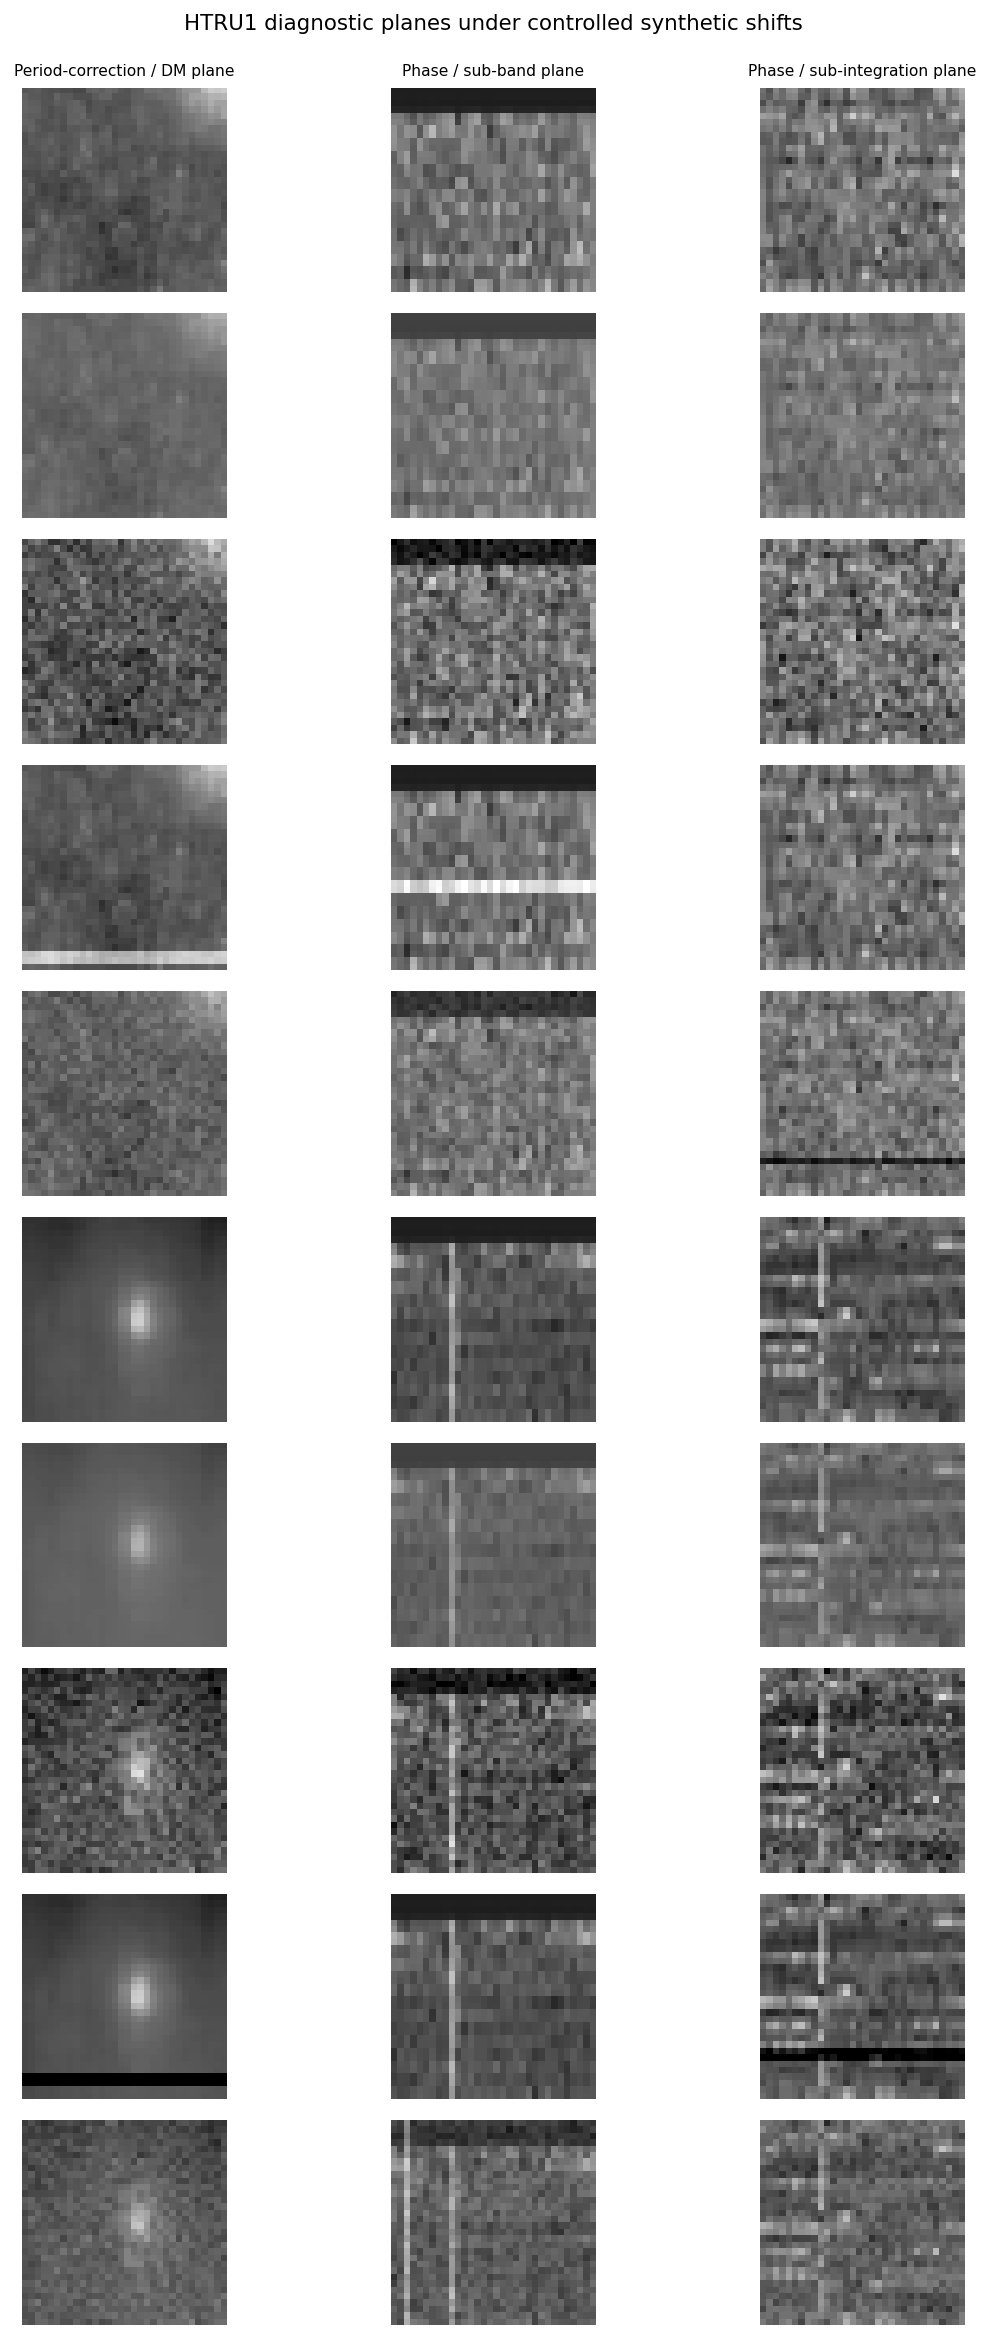

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /content/drive/MyDrive/Pulsar_Experiment_B_YOLO26_FinalSweep/torch_home/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 128MB/s]


Model smoke test PASS: resnet18_clean, logits shape=(2, 2), parameters=11,177,538
Model smoke test PASS: yolo26n_cls_clean, logits shape=(2, 2), parameters=1,533,666
Model smoke test PASS: yolo26s_cls_clean, logits shape=(2, 2), parameters=5,445,570
Model smoke test PASS: yolo26m_cls_clean, logits shape=(2, 2), parameters=10,355,778
Model smoke test PASS: yolo26l_cls_clean, logits shape=(2, 2), parameters=12,837,186
Model smoke test PASS: yolo26x_cls_clean, logits shape=(2, 2), parameters=28,358,626

CELL 1 COMPLETE — DATA, FIXED SPLIT, CORRUPTIONS, RESNET BASELINE, AND ALL YOLO26 SCALES PASSED.
Review the preview at: /content/drive/MyDrive/Pulsar_Experiment_B_YOLO26_FinalSweep/reports/experimentB_corruption_preview.png
If any image corruption looks unrealistic, stop here and refine the proxy before training.
No model has been trained. Next, run Cell 2 in the same Colab runtime.


In [ ]:
# CELL 1 — Final YOLO26 scale-sweep preflight. No training occurs in this cell.
# Tests all released YOLO26 classification sizes and loads the exact saved HTRU1 split.

import os, sys, json, time, hashlib, pickle, shutil, tarfile, urllib.request, subprocess, warnings
from pathlib import Path
from datetime import datetime, timezone

# YOLO26 classification checkpoints require a recent Ultralytics release.
try:
    import ultralytics
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
    import ultralytics  # Import again after installation so the module name exists below.

from google.colab import drive
drive.mount('/content/drive')

# Keep caches and durable study artifacts on Drive; extracted arrays remain in temporary Colab storage.
BASE_PROJECT = Path('/content/drive/MyDrive/Pulsar_Experiment_B_Robustness')
PROJECT = Path('/content/drive/MyDrive/Pulsar_Experiment_B_YOLO26_FinalSweep')
RAW_DIR = PROJECT / 'raw'
SPLIT_DIR = PROJECT / 'splits'
MODEL_DIR = PROJECT / 'models'
REPORT_DIR = PROJECT / 'reports'
CACHE_DIR = PROJECT / 'robustness_cache'
TORCH_HOME = PROJECT / 'torch_home'
LOCAL_WORK = Path('/content/yolo26_final_sweep_work')
LOCAL_DATA = LOCAL_WORK / 'dataset'
for p in [RAW_DIR, SPLIT_DIR, MODEL_DIR, REPORT_DIR, CACHE_DIR, TORCH_HOME, LOCAL_WORK]:
    p.mkdir(parents=True, exist_ok=True)
os.environ['TORCH_HOME'] = str(TORCH_HOME)
os.environ['YOLO_CONFIG_DIR'] = str(PROJECT / 'ultralytics_config')
Path(os.environ['YOLO_CONFIG_DIR']).mkdir(parents=True, exist_ok=True)
PRETRAINED_DIR = PROJECT / 'pretrained'
PRETRAINED_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(PRETRAINED_DIR)  # keep official downloaded weights on Drive

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPyImage
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.models import resnet18, ResNet18_Weights, mobilenet_v3_small, MobileNet_V3_Small_Weights
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, roc_auc_score, balanced_accuracy_score, precision_score, recall_score
from ultralytics import YOLO

# ------------------------ Fixed experiment configuration ------------------------
DATA_URL = 'https://zenodo.org/records/3205409/files/htru1-batches-py.tar.gz?download=1'
DATA_MD5 = 'e7b063301ada3eb50f212afeea185a36'
ARCHIVE_PATH = RAW_DIR / 'htru1-batches-py.tar.gz'
SPLIT_PATH_OLD = BASE_PROJECT / 'splits' / 'train_val_indices_seed42.npz'
SPLIT_PATH = SPLIT_DIR / 'train_val_indices_seed42.npz'
SEED = 42
IMG_SIZE = 128
BATCH_SIZE = 64
NUM_WORKERS = 2
MAX_EPOCHS = 20
EARLY_STOPPING_PATIENCE = 5
SESSION_BUDGET_MINUTES = 300
TOP_K = 100
BENCHMARK_N = 384
BENCH_BATCH_SIZES = [1, 64]
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type != 'cuda':
    raise RuntimeError('No GPU detected. In Colab select Runtime > Change runtime type > GPU, then rerun Cell 1.')
torch.set_num_threads(2)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

print('=' * 78)
print('YOLO26 FINAL SCALE SWEEP — HTRU1 PREFLIGHT')
print('UTC:', datetime.now(timezone.utc).isoformat())
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__, '| torchvision:', torchvision.__version__, '| Ultralytics:', ultralytics.__version__)
print('Drive output:', PROJECT)
print('Training epochs:', MAX_EPOCHS, '| early-stopping patience:', EARLY_STOPPING_PATIENCE)
print('Final matched sweep: ResNet18 clean/shiftaug + YOLO26n/s/m/l/x clean/shiftaug (12 model runs)')
print('Official HTRU1 test batch will not be evaluated in this experiment because it was examined in earlier work.')
print('=' * 78)

# ------------------------ Download and verify HTRU1 archive ------------------------
def md5_file(path):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(4 * 1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

# Reuse the verified archive downloaded during the earlier HTRU1 CLAHE study when available.
PRIOR_ARCHIVE_PATH = BASE_PROJECT / 'raw' / 'htru1-batches-py.tar.gz'
LEGACY_ARCHIVE_PATH = Path('/content/drive/MyDrive/Pulsar_CLAHE_ResNet18_Study/raw/htru1-batches-py.tar.gz')
if not ARCHIVE_PATH.exists():
    candidate_archive = next((p for p in [PRIOR_ARCHIVE_PATH, LEGACY_ARCHIVE_PATH] if p.exists()), None)
    if candidate_archive is not None:
        candidate_md5 = md5_file(candidate_archive)
        if candidate_md5 == DATA_MD5:
            ARCHIVE_PATH = candidate_archive
            print('Reusing verified HTRU1 archive on Drive; no second archive download needed.')
        else:
            print('Available prior archive failed MD5; a fresh verified download will be created in the YOLO26 project.')

if ARCHIVE_PATH.exists():
    existing_md5 = md5_file(ARCHIVE_PATH)
    if existing_md5 != DATA_MD5:
        raise RuntimeError(f'Existing HTRU1 archive failed MD5 verification: {existing_md5}. File retained for inspection: {ARCHIVE_PATH}')
    print('HTRU1 archive already exists on Drive; MD5 PASS.')
else:
    part = ARCHIVE_PATH.with_suffix('.tar.gz.part')
    if part.exists():
        part.unlink()  # This archive is only ~183 MB; restart partial download cleanly.
    print('Downloading official HTRU1 archive to Drive...')
    request = urllib.request.Request(DATA_URL, headers={'User-Agent': 'Mozilla/5.0 HTRU1-Experiment-B'})
    with urllib.request.urlopen(request, timeout=90) as response, open(part, 'wb') as f:
        expected = response.headers.get('Content-Length')
        total = 0
        while True:
            block = response.read(4 * 1024 * 1024)
            if not block:
                break
            f.write(block)
            total += len(block)
            if total and total % (32 * 1024 * 1024) < len(block):
                print(f'  Downloaded {total / 1e6:.0f} MB')
        f.flush()
        os.fsync(f.fileno())
    got = md5_file(part)
    if got != DATA_MD5:
        part.unlink(missing_ok=True)
        raise RuntimeError(f'HTRU1 MD5 mismatch. Expected {DATA_MD5}, received {got}.')
    os.replace(part, ARCHIVE_PATH)
    print('Archive downloaded and MD5 verified:', got)

# ------------------------ Safe extraction and HTRU1 loading ------------------------
def load_pickle(path):
    with open(path, 'rb') as f:
        return pickle.load(f, encoding='bytes')

def field(obj, name):
    return obj.get(name.encode(), obj.get(name))

def decode_text(x):
    return x.decode('utf-8') if isinstance(x, (bytes, bytearray)) else str(x)

metas = list(LOCAL_DATA.rglob('batches.meta')) if LOCAL_DATA.exists() else []
if metas and all((metas[0].parent / f'data_batch_{i}').exists() for i in range(1, 6)) and (metas[0].parent / 'test_batch').exists():
    DATA_DIR = metas[0].parent
else:
    if LOCAL_DATA.exists():
        shutil.rmtree(LOCAL_DATA)
    LOCAL_DATA.mkdir(parents=True, exist_ok=True)
    print('Extracting verified HTRU1 archive into temporary Colab storage...')
    with tarfile.open(ARCHIVE_PATH, 'r:gz') as tf:
        try:
            tf.extractall(path=LOCAL_DATA, filter='data')
        except TypeError:  # Compatibility with Python versions without tar extraction filters.
            tf.extractall(path=LOCAL_DATA)
    metas = list(LOCAL_DATA.rglob('batches.meta'))
    if not metas:
        raise FileNotFoundError('batches.meta missing after extracting verified archive.')
    DATA_DIR = metas[0].parent

meta = load_pickle(DATA_DIR / 'batches.meta')
class_names = [decode_text(v).lower() for v in field(meta, 'label_names')]
pulsar_ids = [i for i, n in enumerate(class_names) if 'pulsar' in n and 'non' not in n]
if len(pulsar_ids) != 1:
    raise ValueError(f'Could not uniquely identify pulsar class in labels: {class_names}')
pulsar_id = pulsar_ids[0]

train_flat, train_labels = [], []
for b in range(1, 6):
    batch = load_pickle(DATA_DIR / f'data_batch_{b}')
    train_flat.append(np.asarray(field(batch, 'data'), dtype=np.uint8))
    train_labels.append(np.asarray(field(batch, 'labels'), dtype=np.int64))
test_obj = load_pickle(DATA_DIR / 'test_batch')
test_flat = np.asarray(field(test_obj, 'data'), dtype=np.uint8)
test_labels_raw = np.asarray(field(test_obj, 'labels'), dtype=np.int64)

X_train_raw = np.concatenate(train_flat, axis=0).reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1).copy()
y_train = (np.concatenate(train_labels) == pulsar_id).astype(np.int64)  # 0=non-pulsar, 1=pulsar
X_test_raw = test_flat.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1).copy()
y_test = (test_labels_raw == pulsar_id).astype(np.int64)

assert X_train_raw.shape == (50000, 32, 32, 3), X_train_raw.shape
assert X_test_raw.shape == (10000, 32, 32, 3), X_test_raw.shape
assert int(y_train.sum()) == 995, int(y_train.sum())
assert int(y_test.sum()) == 199, int(y_test.sum())
assert X_train_raw.dtype == np.uint8 and X_test_raw.dtype == np.uint8
assert np.isfinite(X_train_raw).all() and np.isfinite(X_test_raw).all()
print('\nHTRU1 data integrity: PASS')
print('Class names in archive:', class_names, '| positive label used by experiment: pulsar=1')
print(f'Training batch: {X_train_raw.shape}; pulsars={y_train.sum():,}; non-pulsars={(y_train == 0).sum():,}')
print(f'Official test batch integrity only: {X_test_raw.shape}; pulsars={y_test.sum():,}; not used for Experiment B evaluation')

# Reuse the exact split from completed Experiment B. Fail closed if it is missing.
if not SPLIT_PATH_OLD.exists():
    raise FileNotFoundError(
        f'Required fixed split not found: {SPLIT_PATH_OLD}. '
        'Run the completed Experiment B Cell 1 first; do not silently generate a new split.'
    )
split_obj = np.load(SPLIT_PATH_OLD)
tr_idx, va_idx = split_obj['train_idx'].astype(np.int64), split_obj['val_idx'].astype(np.int64)
if len(tr_idx) != 42500 or len(va_idx) != 7500 or set(tr_idx) & set(va_idx):
    raise ValueError('Saved HTRU1 split failed size/disjointness checks.')
if len(np.unique(np.concatenate([tr_idx, va_idx]))) != 50000:
    raise ValueError('Saved split does not partition all 50,000 training examples.')
if int(y_train[tr_idx].sum()) != 846 or int(y_train[va_idx].sum()) != 149:
    raise ValueError('Saved split class counts differ from the completed Experiment B split.')
source_split = str(SPLIT_PATH_OLD)
np.savez(SPLIT_PATH, train_idx=tr_idx, val_idx=va_idx)
X_val_raw = X_train_raw[va_idx]
y_val = y_train[va_idx].copy()
y_tr = y_train[tr_idx]
assert set(np.unique(y_val)) == {0, 1}
print('Split source:', source_split)
print(f'Fixed split: train={len(tr_idx):,} (pulsars={y_tr.sum():,}), validation={len(va_idx):,} (pulsars={y_val.sum():,})')

# ------------------------ Controlled image-space stress conditions ------------------------
# These are engineering proxies for image-domain shifts, NOT physically calibrated telescope/RFI simulations.
CORRUPTIONS = [
    'clean', 'contrast_low', 'contrast_high', 'gaussian_noise_mild',
    'gaussian_noise_strong', 'rfi_stripes_mild', 'rfi_stripes_strong', 'combined_stress'
]

def corrupt_images(images, condition, seed=1234):
    images = np.asarray(images, dtype=np.uint8)
    if condition == 'clean':
        return images.copy()
    rng = np.random.default_rng(seed)
    x = images.astype(np.float32)
    if condition == 'contrast_low':
        x = (x - 127.5) * 0.65 + 127.5
    elif condition == 'contrast_high':
        x = (x - 127.5) * 1.35 + 127.5
    elif condition == 'gaussian_noise_mild':
        x = x + rng.normal(0, 8.0, size=x.shape).astype(np.float32)
    elif condition == 'gaussian_noise_strong':
        x = x + rng.normal(0, 18.0, size=x.shape).astype(np.float32)
    elif condition in ('rfi_stripes_mild', 'rfi_stripes_strong', 'combined_stress'):
        if condition == 'combined_stress':
            x = (x - 127.5) * 0.75 + 127.5
            x = x + rng.normal(0, 10.0, size=x.shape).astype(np.float32)
            n_lines, width, strength = 1, 1, 75.0
        elif condition == 'rfi_stripes_mild':
            n_lines, width, strength = 1, 1, 65.0
        else:
            n_lines, width, strength = 2, 2, 110.0
        # Insert narrow artificial bright/dark bands in one selected diagnostic plane per line.
        N, H, W, C = x.shape
        for i in range(N):
            for _ in range(n_lines):
                c = int(rng.integers(0, C))
                sign = 1.0 if rng.random() < 0.75 else -1.0
                if rng.random() < 0.5:
                    pos = int(rng.integers(0, W - width + 1))
                    x[i, :, pos:pos + width, c] += sign * strength
                else:
                    pos = int(rng.integers(0, H - width + 1))
                    x[i, pos:pos + width, :, c] += sign * strength
    else:
        raise KeyError(f'Unknown corruption: {condition}')
    return np.clip(x, 0, 255).astype(np.uint8)

# Normalization is consistent across all PyTorch models and all conditions.
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], dtype=torch.float32).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], dtype=torch.float32).view(1, 3, 1, 1)

def apply_random_shift_augmentation(x):
    """Batch-wise synthetic robustness augmentation for ResNet18-shiftaug; x is float [0,1], NCHW at native 32x32."""
    B, C, H, W = x.shape
    mode = torch.randint(0, 5, (B,), device=x.device)  # 0=identity, 1=contrast, 2=noise, 3=stripes, 4=combined
    contrast = torch.empty((B, 1, 1, 1), device=x.device).uniform_(0.65, 1.35)
    x_contrast = ((x - 0.5) * contrast + 0.5).clamp(0, 1)
    use_contrast = ((mode == 1) | (mode == 4)).view(B, 1, 1, 1)
    x = torch.where(use_contrast, x_contrast, x)
    sigma = torch.empty((B, 1, 1, 1), device=x.device).uniform_(0.025, 0.075)
    noise = torch.randn_like(x) * sigma
    use_noise = ((mode == 2) | (mode == 4)).view(B, 1, 1, 1)
    x = torch.where(use_noise, (x + noise).clamp(0, 1), x)
    use_stripe = ((mode == 3) | (mode == 4))
    if use_stripe.any():
        channels = torch.randint(0, C, (B,), device=x.device)
        hpos = torch.randint(0, H, (B,), device=x.device)
        wpos = torch.randint(0, W, (B,), device=x.device)
        rows = torch.arange(H, device=x.device).view(1, 1, H, 1)
        cols = torch.arange(W, device=x.device).view(1, 1, 1, W)
        one_hot_channel = F.one_hot(channels, num_classes=C).float().view(B, C, 1, 1)
        stripe_mask = ((rows == hpos.view(B, 1, 1, 1)) | (cols == wpos.view(B, 1, 1, 1))).float()
        stripe_mask = stripe_mask * one_hot_channel * use_stripe.float().view(B, 1, 1, 1)
        sign = torch.where(torch.rand((B, 1, 1, 1), device=x.device) < 0.75, 1.0, -1.0)
        x = (x + stripe_mask * sign * 0.30).clamp(0, 1)
    return x

def prepare_batch(raw_chw, device, model_name, shift_augment=False):
    # All models receive the same raw diagnostic planes and bilinear 128x128 resize.
    # Use each pretrained family’s expected input scaling: torchvision ResNet uses ImageNet
    # mean/std; Ultralytics YOLO26 classification uses RGB values scaled to [0,1] by default.
    x = raw_chw.to(device=device, non_blocking=True).float().div_(255.0)
    if shift_augment:
        x = apply_random_shift_augmentation(x)
    x = F.interpolate(x, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)
    if model_name.startswith('resnet18') or model_name.startswith('mobilenet_v3'):
        mean = IMAGENET_MEAN.to(device)
        std = IMAGENET_STD.to(device)
        x = (x - mean) / std
    return x

# ------------------------ Model construction ------------------------
def build_model(model_name):
    """Build a pretrained binary classifier; suffix chooses training augmentation, not architecture."""
    if model_name in ('resnet18_clean', 'resnet18_shiftaug'):
        model = resnet18(weights=ResNet18_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, 2)
        return model
    if model_name.startswith('yolo26'):
        # Names look like yolo26x_cls_shiftaug. Checkpoints are official ImageNet-pretrained
        # Ultralytics classification models, not detection or OBB models.
        scale = model_name[len('yolo26')]
        if scale not in 'nsm lx'.replace(' ', ''):
            raise ValueError(f'Unsupported YOLO26 classification scale in {model_name}')
        checkpoint_name = f'yolo26{scale}-cls.pt'
        wrapper = YOLO(checkpoint_name)
        model = wrapper.model
        head = model.model[-1]
        if not hasattr(head, 'linear') or not isinstance(head.linear, nn.Linear):
            raise RuntimeError(
                f'Expected Ultralytics classification head with Linear layer for {checkpoint_name}; '
                f'found {type(head).__name__}.'
            )
        head.linear = nn.Linear(head.linear.in_features, 2)
        if hasattr(model, 'nc'):
            model.nc = 2
        if hasattr(model, 'names'):
            model.names = {0: 'nonpulsar', 1: 'pulsar'}
        if hasattr(model, 'yaml') and isinstance(model.yaml, dict):
            model.yaml['nc'] = 2
        return model
    raise KeyError(f'Unknown model name: {model_name}')

# ------------------------ Smoke-test corruptions and all model architectures ------------------------
# Ensure image perturbations are valid, reproducible, and change the sample pixels.
smoke_n = min(64, len(X_val_raw))
smoke_images = X_val_raw[:smoke_n]
corruption_smoke = {}
for condition in CORRUPTIONS:
    transformed = corrupt_images(smoke_images, condition, seed=2026)
    assert transformed.shape == smoke_images.shape and transformed.dtype == np.uint8
    assert np.isfinite(transformed).all()
    changed_fraction = float(np.mean(transformed != smoke_images))
    corruption_smoke[condition] = changed_fraction
    if condition != 'clean' and not np.any(transformed != smoke_images):
        raise RuntimeError(f'Corruption {condition} did not alter the smoke-test images.')
    print(f'Corruption smoke test: {condition:24s} changed-pixel fraction={changed_fraction:.4%}')

# Save and display channel-by-channel previews for one pulsar and one non-pulsar.
# HTRU1's 3 channels are separate diagnostic planes, not literal RGB colour bands.
pos_i = int(np.flatnonzero(y_val == 1)[0])
neg_i = int(np.flatnonzero(y_val == 0)[0])
preview_indices = [neg_i, pos_i]
preview_conditions = ['clean', 'contrast_low', 'gaussian_noise_strong', 'rfi_stripes_strong', 'combined_stress']
channel_titles = ['Period-correction / DM plane', 'Phase / sub-band plane', 'Phase / sub-integration plane']
fig, axes = plt.subplots(len(preview_indices) * len(preview_conditions), 3, figsize=(9, 17))
plot_row = 0
for local_i in preview_indices:
    source = X_val_raw[local_i:local_i + 1]
    cls_name = 'PULSAR' if y_val[local_i] == 1 else 'NON-PULSAR'
    for condition in preview_conditions:
        img = corrupt_images(source, condition, seed=101 + local_i)[0]
        for channel in range(3):
            axes[plot_row, channel].imshow(img[:, :, channel], cmap='gray', vmin=0, vmax=255)
            axes[plot_row, channel].axis('off')
            if plot_row == 0:
                axes[plot_row, channel].set_title(channel_titles[channel], fontsize=8)
        axes[plot_row, 0].set_ylabel(f'{cls_name} | {condition}', fontsize=8)
        plot_row += 1
fig.suptitle('HTRU1 diagnostic planes under controlled synthetic shifts', fontsize=11)
fig.tight_layout(rect=[0, 0, 1, 0.985])
PREVIEW_PATH = REPORT_DIR / 'experimentB_corruption_preview.png'
fig.savefig(PREVIEW_PATH, dpi=140, bbox_inches='tight')
plt.close(fig)
print('Saved corruption preview:', PREVIEW_PATH)
display(IPyImage(filename=str(PREVIEW_PATH)))

# Ensure all model heads produce exactly two class logits on the same preprocessed sample.
smoke_raw = torch.from_numpy(np.ascontiguousarray(smoke_images[:2].transpose(0, 3, 1, 2)))
smoke_tensor_resnet = prepare_batch(smoke_raw, DEVICE, 'resnet18_clean', shift_augment=False)
model_smoke = {}
SMOKE_MODEL_NAMES = ['resnet18_clean'] + [f'yolo26{s}_cls_clean' for s in 'nsm lx'.replace(' ', '')]
for model_name in SMOKE_MODEL_NAMES:
    model = build_model(model_name).to(DEVICE).eval()
    smoke_tensor = prepare_batch(smoke_raw, DEVICE, model_name, shift_augment=False)
    with torch.inference_mode():
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=True):
            output = model(smoke_tensor)
    if isinstance(output, (list, tuple)):
        candidates = [z for z in output if torch.is_tensor(z) and z.ndim == 2]
        if not candidates:
            raise RuntimeError(f'No [batch, classes] logits returned by {model_name}: {type(output)}')
        output = candidates[-1]
    assert torch.is_tensor(output) and tuple(output.shape) == (2, 2), (model_name, type(output), getattr(output, 'shape', None))
    parameter_count = sum(p.numel() for p in model.parameters())
    model_smoke[model_name] = {'output_shape': list(output.shape), 'finite_logits': bool(torch.isfinite(output.float()).all().item()), 'parameter_count': int(parameter_count)}
    assert model_smoke[model_name]['finite_logits']
    print(f'Model smoke test PASS: {model_name}, logits shape={tuple(output.shape)}, parameters={parameter_count:,}')
    del model, output
    torch.cuda.empty_cache()

# Save preflight state; Cell 2 uses the arrays and functions currently in memory.
verification = {
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'dataset': 'HTRU1 Batched Dataset, Zenodo record 3205409',
    'archive_path': str(ARCHIVE_PATH),
    'archive_md5': md5_file(ARCHIVE_PATH),
    'train_shape': list(X_train_raw.shape),
    'test_shape_integrity_only': list(X_test_raw.shape),
    'train_positive': int(y_train.sum()),
    'train_negative': int((y_train == 0).sum()),
    'validation_count': int(len(y_val)),
    'validation_positive': int(y_val.sum()),
    'validation_negative': int((y_val == 0).sum()),
    'split_source': source_split,
    'seed': SEED,
    'gpu': torch.cuda.get_device_name(0),
    'corruption_pixel_change_smoke': corruption_smoke,
    'model_smoke_tests': model_smoke,
    'yolo_family': 'YOLO26 classification (n/s/m/l/x), pretrained on ImageNet; all use native [0,1] input scaling',
    'preview_path': str(PREVIEW_PATH),
    'official_test_not_used': True,
    'important_limit': 'Image-space corruptions are synthetic robustness proxies, not a calibrated or time-separated MeerKAT RFI benchmark.'
}
(REPORT_DIR / 'cell1_preflight.json').write_text(json.dumps(verification, indent=2))
print('\n' + '=' * 78)
print('CELL 1 COMPLETE — DATA, FIXED SPLIT, CORRUPTIONS, RESNET BASELINE, AND ALL YOLO26 SCALES PASSED.')
print('Review the preview at:', PREVIEW_PATH)
print('If any image corruption looks unrealistic, stop here and refine the proxy before training.')
print('No model has been trained. Next, run Cell 2 in the same Colab runtime.')
print('=' * 78)


In [ ]:
# CELL 2 — Matched final sweep: ResNet18 references + every YOLO26 classification scale.
# Trains clean and shift-augmented variants, measures robustness, then benchmarks inference.

import os, sys, json, time, math, random, shutil, traceback
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import average_precision_score, roc_auc_score, balanced_accuracy_score, precision_score, recall_score

if 'X_train_raw' not in globals() or 'corrupt_images' not in globals() or 'build_model' not in globals():
    raise RuntimeError('Cell 1 state is missing. Run Cell 1 successfully in this runtime, then rerun Cell 2.')
if not torch.cuda.is_available():
    raise RuntimeError('GPU not detected. Reconnect a GPU runtime before running Cell 2.')

# One fixed seed only. No multi-seed replication. The held-out validation split is reused for robustness analysis.
set_seed = 42
max_epochs = 20
early_patience = 5
session_budget_minutes = 300
batch_size = 64
num_workers = 2
top_k = 100
benchmark_n = min(384, len(X_val_raw))
bench_batch_sizes = [1, 64]
DEVICE = torch.device('cuda')
SESSION_START = time.monotonic()
SESSION_DEADLINE = SESSION_START + session_budget_minutes * 60

MODEL_NAMES = ['resnet18_clean', 'resnet18_shiftaug'] + [
    f'yolo26{scale}_cls_{regime}'
    for scale in 'nsm lx'.replace(' ', '')
    for regime in ('clean', 'shiftaug')
]
MODEL_DIR = PROJECT / 'models'
REPORT_DIR = PROJECT / 'reports'
CACHE_DIR = PROJECT / 'robustness_cache'
for p in [MODEL_DIR, REPORT_DIR, CACHE_DIR]:
    p.mkdir(parents=True, exist_ok=True)


def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def atomic_torch_save(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    local_tmp = Path('/content') / (path.name + '.tmp')
    torch.save(obj, local_tmp)
    drive_tmp = path.with_name(path.name + '.tmp')
    shutil.copy2(local_tmp, drive_tmp)
    os.replace(drive_tmp, path)
    local_tmp.unlink(missing_ok=True)


def atomic_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2, default=str))
    os.replace(tmp, path)


def output_logits(model, x):
    out = model(x)
    if isinstance(out, (tuple, list)):
        tensor_outputs = [z for z in out if torch.is_tensor(z) and z.ndim == 2]
        if not tensor_outputs:
            raise RuntimeError(f'Model returned unsupported output type: {type(out)}')
        out = tensor_outputs[-1]
    if out.ndim != 2 or out.shape[1] != 2:
        raise RuntimeError(f'Expected [batch,2] class logits, received {tuple(out.shape)}')
    return out


class HTRUIndexedDataset(Dataset):
    def __init__(self, images, labels, indices):
        self.images = images
        self.labels = labels
        self.indices = np.asarray(indices, dtype=np.int64)
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, ix):
        source_index = int(self.indices[ix])
        image = self.images[source_index]
        chw = np.ascontiguousarray(image.transpose(2, 0, 1))
        return torch.from_numpy(chw), torch.tensor(int(self.labels[source_index]), dtype=torch.long)


def compute_metrics(y_true, probs, k=top_k):
    y_true = np.asarray(y_true, dtype=np.int32)
    probs = np.asarray(probs, dtype=np.float64)
    pred = (probs >= 0.5).astype(np.int32)
    order = np.argsort(probs)[::-1]
    k_eff = min(int(k), len(order))
    top_positive = int(y_true[order[:k_eff]].sum())
    return {
        'AP': float(average_precision_score(y_true, probs)),
        'ROC_AUC': float(roc_auc_score(y_true, probs)),
        'balanced_accuracy_at_0.5': float(balanced_accuracy_score(y_true, pred)),
        'precision_at_0.5': float(precision_score(y_true, pred, zero_division=0)),
        'recall_at_0.5': float(recall_score(y_true, pred, zero_division=0)),
        'top_k': int(k_eff),
        'top_k_true_pulsars': top_positive,
        'precision_at_top_k': float(top_positive / k_eff) if k_eff else 0.0,
        'recall_at_top_k': float(top_positive / max(int(y_true.sum()), 1)),
        'positive_prevalence': float(y_true.mean()),
        'false_positives_at_0.5': int(np.sum((y_true == 0) & (pred == 1))),
        'false_negatives_at_0.5': int(np.sum((y_true == 1) & (pred == 0))),
    }


def evaluate_model(model, model_name, images, labels, device=DEVICE, batch=64, use_amp=True):
    model.eval()
    dataset = HTRUIndexedDataset(images, labels, np.arange(len(labels)))
    loader = DataLoader(dataset, batch_size=batch, shuffle=False, num_workers=num_workers,
                        pin_memory=(device.type == 'cuda'), persistent_workers=(num_workers > 0))
    scores = []
    with torch.inference_mode():
        for raw, _labels in loader:
            x = prepare_batch(raw, device, model_name, shift_augment=False)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(device.type == 'cuda' and use_amp)):
                logits = output_logits(model, x)
            probs = torch.softmax(logits.float(), dim=1)[:, 1]
            scores.extend(probs.detach().cpu().numpy().tolist())
    del loader, dataset
    return np.asarray(scores, dtype=np.float64)


def save_epoch_log(path, row):
    path = Path(path)
    exists = path.exists()
    with open(path, 'a', newline='', encoding='utf-8') as f:
        pd.DataFrame([row]).to_csv(f, header=not exists, index=False)
        f.flush()
        os.fsync(f.fileno())


def train_one_model(model_name):
    run_dir = MODEL_DIR / model_name
    run_dir.mkdir(parents=True, exist_ok=True)
    best_path = run_dir / 'best.pt'
    last_path = run_dir / 'last.pt'
    completed_path = run_dir / 'completed.json'
    epoch_csv = run_dir / 'epoch_metrics.csv'

    if completed_path.exists() and best_path.exists():
        result = json.loads(completed_path.read_text())
        print(f'Already completed: {model_name} (best val AP={result["best_val_AP"]:.4f}); skipping training.')
        return result

    set_all_seeds(set_seed)
    model = build_model(model_name).to(DEVICE)
    counts = np.bincount(y_tr, minlength=2).astype(np.float32)
    class_weights = len(y_tr) / (2.0 * counts)
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=DEVICE))
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=5e-4)
    scaler = torch.amp.GradScaler('cuda', enabled=True)
    generator = torch.Generator().manual_seed(set_seed + 900)
    train_ds = HTRUIndexedDataset(X_train_raw, y_train, tr_idx)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=num_workers,
                              pin_memory=True, generator=generator, persistent_workers=(num_workers > 0))

    start_epoch, best_ap, best_epoch, no_improve, resumed = 1, -1.0, 0, 0, False
    if last_path.exists():
        ckpt = torch.load(last_path, map_location='cpu', weights_only=False)
        model.load_state_dict(ckpt['model_state_dict'])
        optimizer.load_state_dict(ckpt['optimizer_state_dict'])
        scaler.load_state_dict(ckpt['scaler_state_dict'])
        start_epoch = int(ckpt['epoch']) + 1
        best_ap = float(ckpt.get('best_val_AP', -1.0))
        best_epoch = int(ckpt.get('best_epoch', 0))
        no_improve = int(ckpt.get('no_improve', 0))
        if ckpt.get('loader_generator_state') is not None:
            generator.set_state(ckpt['loader_generator_state'])
        if ckpt.get('rng_torch') is not None:
            torch.set_rng_state(ckpt['rng_torch'].cpu())
        if ckpt.get('rng_cuda') is not None:
            torch.cuda.set_rng_state_all([s.cpu() for s in ckpt['rng_cuda']])
        if ckpt.get('rng_numpy') is not None:
            np.random.set_state(ckpt['rng_numpy'])
        if ckpt.get('rng_python') is not None:
            random.setstate(ckpt['rng_python'])
        resumed = True
        print(f'Resuming {model_name} from epoch {start_epoch}.')

    use_shift_aug = model_name.endswith('_shiftaug')
    print(f'\n=== Training {model_name} | pretrained backbone | class-weighted loss | seed={set_seed} ===')
    history = []
    for epoch in range(start_epoch, max_epochs + 1):
        if time.monotonic() >= SESSION_DEADLINE:
            print('Session budget reached. Checkpoints are saved; rerun Cell 2 to resume.')
            del model, optimizer, scaler, train_loader
            torch.cuda.empty_cache()
            return {'model': model_name, 'status': 'paused', 'last_epoch': epoch - 1}

        model.train()
        loss_sum, seen = 0.0, 0
        for raw, labels in train_loader:
            x = prepare_batch(raw, DEVICE, model_name, shift_augment=use_shift_aug)
            labels = labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=True):
                logits = output_logits(model, x)
                loss = criterion(logits, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            loss_sum += float(loss.detach().item()) * len(labels)
            seen += len(labels)

        train_loss = loss_sum / max(seen, 1)
        y_val_local = y_train[va_idx]
        val_scores = evaluate_model(model, model_name, X_train_raw[va_idx], y_val_local, batch=batch_size)
        val_metrics = compute_metrics(y_val_local, val_scores)
        row = {
            'model': model_name, 'seed': set_seed, 'epoch': epoch,
            'train_loss': train_loss, 'val_AP': val_metrics['AP'], 'val_ROC_AUC': val_metrics['ROC_AUC'],
            'val_precision_at_top100': val_metrics['precision_at_top_k'],
            'val_recall_at_top100': val_metrics['recall_at_top_k'],
            'timestamp_utc': datetime.now(timezone.utc).isoformat(),
        }
        save_epoch_log(epoch_csv, row)
        history.append(row)
        print(f'Epoch {epoch:02d}/{max_epochs} | loss={train_loss:.5f} | val AP={val_metrics["AP"]:.4f} | '
              f'val AUC={val_metrics["ROC_AUC"]:.4f} | P@100={val_metrics["precision_at_top_k"]:.3f}')

        improved = val_metrics['AP'] > best_ap + 1e-6
        if improved:
            best_ap = val_metrics['AP']
            best_epoch = epoch
            no_improve = 0
            atomic_torch_save({
                'model_name': model_name, 'seed': set_seed, 'epoch': epoch,
                'model_state_dict': {k: v.detach().cpu() for k, v in model.state_dict().items()},
                'best_val_AP': best_ap, 'best_val_metrics': val_metrics,
                'class_weights': class_weights.tolist(), 'image_size': IMG_SIZE,
                'label_mapping': {'0': 'non-pulsar', '1': 'pulsar'},
            }, best_path)
            print('  Best AP checkpoint saved.')
        else:
            no_improve += 1

        last_payload = {
            'model_name': model_name, 'epoch': epoch,
            'model_state_dict': model.state_dict(), 'optimizer_state_dict': optimizer.state_dict(),
            'scaler_state_dict': scaler.state_dict(), 'best_val_AP': best_ap,
            'best_epoch': best_epoch, 'no_improve': no_improve,
            'class_weights': class_weights.tolist(), 'loader_generator_state': generator.get_state(),
            'rng_torch': torch.get_rng_state(), 'rng_cuda': torch.cuda.get_rng_state_all(),
            'rng_numpy': np.random.get_state(), 'rng_python': random.getstate(),
        }
        atomic_torch_save(last_payload, last_path)
        atomic_json(REPORT_DIR / 'latest_progress.json', {
            'status': 'training', 'active_model': model_name, 'completed_epoch': epoch,
            'best_validation_AP': best_ap, 'updated_utc': datetime.now(timezone.utc).isoformat()
        })

        if no_improve >= early_patience:
            print(f'Early stopping at epoch {epoch}; best AP was epoch {best_epoch}.')
            break

    if not best_path.exists():
        raise RuntimeError(f'No best checkpoint exists for {model_name}.')
    best_ckpt = torch.load(best_path, map_location='cpu', weights_only=False)
    result = {
        'model': model_name, 'status': 'completed', 'seed': set_seed,
        'best_epoch': int(best_ckpt['epoch']), 'best_val_AP': float(best_ckpt['best_val_AP']),
        'best_val_metrics': best_ckpt['best_val_metrics'], 'best_checkpoint': str(best_path),
        'epochs_logged_this_session': len(history), 'resumed': resumed,
        'max_epochs': max_epochs, 'early_stopping_patience': early_patience,
        'training_augmentation': 'controlled random contrast/noise/stripe proxy' if use_shift_aug else 'none (clean training)',
    }
    atomic_json(completed_path, result)
    print(f'Completed {model_name}: best validation AP={result["best_val_AP"]:.4f} at epoch {result["best_epoch"]}.')
    del model, optimizer, scaler, train_loader, train_ds
    torch.cuda.empty_cache()
    return result


def load_best_model(model_name, device=DEVICE):
    model = build_model(model_name)
    checkpoint = torch.load(MODEL_DIR / model_name / 'best.pt', map_location='cpu', weights_only=False)
    model.load_state_dict(checkpoint['model_state_dict'])
    return model.to(device).eval(), checkpoint

# ------------------------ Phase A: train/resume model set ------------------------
print('=' * 78)
print('PHASE A — MATCHED TRAINING (single fixed seed; no seed replication)')
print('Models:', ', '.join(MODEL_NAMES))
print('All runs: same saved split, seed, batch size, AdamW/loss, epoch budget, and early stopping.')
print('=' * 78)

training_results = []
for name in MODEL_NAMES:
    result = train_one_model(name)
    training_results.append(result)
    atomic_json(REPORT_DIR / 'training_progress.json', {
        'updated_utc': datetime.now(timezone.utc).isoformat(),
        'results': training_results,
    })
    if result.get('status') == 'paused':
        print('Training paused safely. Rerun Cell 2 to resume from Drive checkpoints.')
        raise SystemExit('YOLO26 sweep paused at an epoch boundary; rerun Cell 2 to resume from Drive checkpoints.')

pd.DataFrame([
    {'model': r['model'], 'best_epoch': r['best_epoch'], 'best_val_AP': r['best_val_AP'],
     'best_val_ROC_AUC': r['best_val_metrics']['ROC_AUC'],
     'P@100': r['best_val_metrics']['precision_at_top_k'],
     'R@100': r['best_val_metrics']['recall_at_top_k']}
    for r in training_results if r.get('status') == 'completed'
]).to_csv(REPORT_DIR / 'model_training_summary.csv', index=False)

# ------------------------ Phase B: robustness evaluations ------------------------
print('\n' + '=' * 78)
print('PHASE B — ROBUSTNESS EVALUATION ON THE SAME FIXED VALIDATION CANDIDATES')
print('=' * 78)
robust_rows = []
clean_scores_by_model = {}
robust_progress_path = REPORT_DIR / 'robustness_progress.csv'
if robust_progress_path.exists():
    _prior = pd.read_csv(robust_progress_path)
    robust_rows = _prior.to_dict('records')
else:
    _prior = pd.DataFrame()
prior_keys = {(str(r['model']), str(r['condition'])) for r in robust_rows}

for model_name in MODEL_NAMES:
    # Reuse prior clean scores when this cell is rerun after an interruption.
    clean_score_file = REPORT_DIR / f'validation_clean_scores_{model_name}.npz'
    if clean_score_file.exists():
        _cs = np.load(clean_score_file)
        clean_scores_by_model[model_name] = _cs['y_score'].copy()
    model, ckpt = load_best_model(model_name, DEVICE)
    clean_scores = clean_scores_by_model.get(model_name)
    for condition in CORRUPTIONS:
        if (model_name, condition) in prior_keys:
            print(f'Skipping saved robustness result: {model_name} / {condition}')
            continue
        cache_path = CACHE_DIR / f'val_{condition}_seed2026.npy'
        if condition == 'clean':
            images_condition = X_val_raw
        else:
            if cache_path.exists():
                images_condition = np.load(cache_path, mmap_mode='r', allow_pickle=False)
                if images_condition.shape != X_val_raw.shape:
                    cache_path.unlink(missing_ok=True)
                    images_condition = corrupt_images(X_val_raw, condition, seed=2026)
                    np.save(cache_path, images_condition, allow_pickle=False)
            else:
                images_condition = corrupt_images(X_val_raw, condition, seed=2026)
                np.save(cache_path, images_condition, allow_pickle=False)
        scores = evaluate_model(model, model_name, images_condition, y_val, batch=batch_size)
        metrics = compute_metrics(y_val, scores)
        if condition == 'clean':
            clean_scores = scores.copy()
            clean_scores_by_model[model_name] = scores.copy()
            np.savez_compressed(clean_score_file, y_true=y_val, y_score=scores)
        score_output = REPORT_DIR / f'validation_scores_{model_name}_{condition}.npz'
        np.savez_compressed(score_output, y_true=y_val, y_score=scores)
        clean_ap = compute_metrics(y_val, clean_scores)['AP'] if clean_scores is not None else float('nan')
        _row = {
            'model': model_name, 'condition': condition,
            **metrics,
            'AP_absolute_delta_vs_clean': float(metrics['AP'] - clean_ap),
            'AP_relative_change_pct_vs_clean': float(100.0 * (metrics['AP'] - clean_ap) / max(clean_ap, 1e-9)),
            'evaluation_examples': len(y_val), 'seed': set_seed, 'score_file': str(score_output),
        }
        robust_rows.append(_row)
        prior_keys.add((model_name, condition))
        pd.DataFrame(robust_rows).to_csv(robust_progress_path, index=False)
        print(f'{model_name:26s} | {condition:24s} | AP={metrics["AP"]:.4f} | AUC={metrics["ROC_AUC"]:.4f} | P@100={metrics["precision_at_top_k"]:.3f}')
    del model
    torch.cuda.empty_cache()

robust_df = pd.DataFrame(robust_rows)
robust_df = robust_df.drop_duplicates(subset=['model', 'condition'], keep='last')
robust_df.to_csv(REPORT_DIR / 'robustness_metrics.csv', index=False)

# ------------------------ Phase C: latency / throughput benchmark ------------------------
def benchmark_pipeline(model, model_name, images, device, batch_size, n_images=BENCHMARK_N):
    device = torch.device(device)
    model = model.to(device).eval()
    n_images = min(int(n_images), len(images))
    # Warm-up the actual image-to-logit path, including transfer, resize, and normalization.
    warm_n = min(batch_size, n_images)
    warm_raw = torch.from_numpy(np.ascontiguousarray(images[:warm_n].transpose(0, 3, 1, 2)))
    with torch.inference_mode():
        for _ in range(5 if batch_size == 1 else 2):
            x = prepare_batch(warm_raw, device, model_name, shift_augment=False)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(device.type == 'cuda')):
                _ = output_logits(model, x)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        started = time.perf_counter()
        seen = 0
        for start in range(0, n_images, batch_size):
            stop = min(start + batch_size, n_images)
            raw = torch.from_numpy(np.ascontiguousarray(images[start:stop].transpose(0, 3, 1, 2)))
            x = prepare_batch(raw, device, model_name, shift_augment=False)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(device.type == 'cuda')):
                _ = output_logits(model, x)
            seen += stop - start
        if device.type == 'cuda':
            torch.cuda.synchronize()
        elapsed = time.perf_counter() - started
    batches = math.ceil(n_images / batch_size)
    return {
        'device': str(device), 'batch_size': int(batch_size), 'images_timed': int(seen),
        'elapsed_seconds': float(elapsed),
        'pipeline_images_per_second': float(seen / max(elapsed, 1e-9)),
        'mean_batch_latency_ms': float(1000.0 * elapsed / max(batches, 1)),
        'mean_per_image_ms': float(1000.0 * elapsed / max(seen, 1)),
        'gpu_amp': bool(device.type == 'cuda'),
        'timing_scope': 'NumPy uint8 image batch -> tensor transfer -> resize/normalize -> model forward; excludes PFD decoding and file I/O',
    }

print('\n' + '=' * 78)
print('PHASE C — INFERENCE PIPELINE LATENCY / THROUGHPUT FOR ALL MATCHED MODELS')
print('These numbers are for in-memory HTRU1 diagnostic images; they do not include PFD parsing.')
print('=' * 78)
speed_progress_path = REPORT_DIR / 'throughput_progress.csv'
if speed_progress_path.exists():
    speed_rows = pd.read_csv(speed_progress_path).to_dict('records')
else:
    speed_rows = []
speed_done = {(str(r['model']), str(r['device']), int(r['batch_size'])) for r in speed_rows}
for model_name in MODEL_NAMES:
    model, _ = load_best_model(model_name, DEVICE)
    # CPU baseline (FP32).
    for bs in bench_batch_sizes:
        if (model_name, 'cpu', int(bs)) not in speed_done:
            cpu_result = benchmark_pipeline(model, model_name, X_val_raw, 'cpu', bs)
            row = {'model': model_name, **cpu_result}
            speed_rows.append(row)
            pd.DataFrame(speed_rows).to_csv(speed_progress_path, index=False)
            speed_done.add((model_name, 'cpu', int(bs)))
            print(f'{model_name:26s} CPU batch={bs:3d} | {cpu_result["pipeline_images_per_second"]:8.1f} img/s | '
                  f'{cpu_result["mean_per_image_ms"]:7.2f} ms/img')
        else:
            print(f'Skipping saved CPU speed row: {model_name} batch={bs}')
    # GPU measurement (autocast FP16 on supported CUDA).
    for bs in bench_batch_sizes:
        if (model_name, 'cuda', int(bs)) not in speed_done:
            gpu_result = benchmark_pipeline(model, model_name, X_val_raw, 'cuda', bs)
            row = {'model': model_name, **gpu_result}
            speed_rows.append(row)
            pd.DataFrame(speed_rows).to_csv(speed_progress_path, index=False)
            speed_done.add((model_name, 'cuda', int(bs)))
            print(f'{model_name:26s} GPU batch={bs:3d} | {gpu_result["pipeline_images_per_second"]:8.1f} img/s | '
                  f'{gpu_result["mean_per_image_ms"]:7.2f} ms/img')
        else:
            print(f'Skipping saved GPU speed row: {model_name} batch={bs}')
    del model
    torch.cuda.empty_cache()

speed_df = pd.DataFrame(speed_rows)
speed_df = speed_df.drop_duplicates(subset=['model', 'device', 'batch_size'], keep='last')
speed_df.to_csv(REPORT_DIR / 'inference_throughput.csv', index=False)

# ------------------------ Figures and final report ------------------------
fig, ax = plt.subplots(figsize=(12, 6))
for model_name in MODEL_NAMES:
    subset = robust_df[robust_df['model'] == model_name]
    ax.plot(subset['condition'], subset['AP'], marker='o', label=model_name)
ax.set_ylabel('Average precision (AP)')
ax.set_xlabel('Validation image condition')
ax.set_title('HTRU1 validation robustness under controlled image-space shifts')
ax.tick_params(axis='x', rotation=30)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(REPORT_DIR / 'yolo26_final_robustness_ap_by_condition.png', dpi=160)
plt.close(fig)

speed_plot_df = speed_df[speed_df['batch_size'] == 1].copy()
labels_plot = [f'{r.model}\n{r.device}' for r in speed_plot_df.itertuples()]
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(labels_plot, speed_plot_df['pipeline_images_per_second'])
ax.set_ylabel('Images/second (higher is faster)')
ax.set_title('Single-image pipeline throughput: preprocessing + model forward')
ax.tick_params(axis='x', rotation=30)
fig.tight_layout()
fig.savefig(REPORT_DIR / 'yolo26_final_single_image_throughput.png', dpi=160)
plt.close(fig)

# Compact model summary: clean AP, average/worst robustness, matched ResNet delta, and speed.
summary_rows = []
resnet_clean = robust_df[(robust_df['model'] == 'resnet18_clean') & (robust_df['condition'] == 'clean')].iloc[0]
resnet_aug = robust_df[(robust_df['model'] == 'resnet18_shiftaug') & (robust_df['condition'] == 'clean')].iloc[0]
resnet_clean_stress = robust_df[(robust_df['model'] == 'resnet18_clean') & (robust_df['condition'] != 'clean')]['AP'].mean()
resnet_aug_stress = robust_df[(robust_df['model'] == 'resnet18_shiftaug') & (robust_df['condition'] != 'clean')]['AP'].mean()
best_resnet_clean_ap = float(max(resnet_clean['AP'], resnet_aug['AP']))
best_resnet_stress_ap = float(max(resnet_clean_stress, resnet_aug_stress))
for name in MODEL_NAMES:
    part = robust_df[robust_df['model'] == name]
    clean_row = part[part['condition'] == 'clean'].iloc[0]
    corrupted = part[part['condition'] != 'clean']
    worst_row = corrupted.loc[corrupted['AP'].idxmin()]
    speed_gpu1 = speed_df[(speed_df['model'] == name) & (speed_df['device'] == 'cuda') & (speed_df['batch_size'] == 1)].iloc[0]
    speed_gpu64 = speed_df[(speed_df['model'] == name) & (speed_df['device'] == 'cuda') & (speed_df['batch_size'] == 64)].iloc[0]
    matched_resnet_name = 'resnet18_shiftaug' if name.endswith('_shiftaug') else 'resnet18_clean'
    matched_resnet_clean = robust_df[(robust_df['model'] == matched_resnet_name) & (robust_df['condition'] == 'clean')]['AP'].iloc[0]
    matched_resnet_stress = robust_df[(robust_df['model'] == matched_resnet_name) & (robust_df['condition'] != 'clean')]['AP'].mean()
    mean_stress_ap = float(corrupted['AP'].mean())
    summary_rows.append({
        'model': name,
        'training_regime': 'shift_augmented' if name.endswith('_shiftaug') else 'clean',
        'clean_validation_AP': float(clean_row['AP']),
        'clean_validation_ROC_AUC': float(clean_row['ROC_AUC']),
        'clean_precision_at_top100': float(clean_row['precision_at_top_k']),
        'mean_corruption_AP_7_conditions': mean_stress_ap,
        'mean_corruption_P_at_top100': float(corrupted['precision_at_top_k'].mean()),
        'worst_corruption': worst_row['condition'],
        'worst_corruption_AP': float(worst_row['AP']),
        'delta_clean_AP_vs_matched_ResNet': float(clean_row['AP'] - matched_resnet_clean),
        'delta_mean_corruption_AP_vs_matched_ResNet': float(mean_stress_ap - matched_resnet_stress),
        'delta_clean_AP_vs_best_ResNet': float(clean_row['AP'] - best_resnet_clean_ap),
        'delta_mean_corruption_AP_vs_best_ResNet': float(mean_stress_ap - best_resnet_stress_ap),
        'GPU_batch1_images_per_second': float(speed_gpu1['pipeline_images_per_second']),
        'GPU_batch64_images_per_second': float(speed_gpu64['pipeline_images_per_second']),
        'best_validation_checkpoint': str(MODEL_DIR / name / 'best.pt'),
    })
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(REPORT_DIR / 'yolo26_final_model_summary.csv', index=False)

def df_to_markdown(df):
    cols = list(df.columns)
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return f'{float(v):.4f}'
        return str(v).replace('|', '\\|')
    lines = ['| ' + ' | '.join(cols) + ' |', '| ' + ' | '.join(['---'] * len(cols)) + ' |']
    for _, row in df.iterrows():
        lines.append('| ' + ' | '.join(fmt(row[c]) for c in cols) + ' |')
    return '\n'.join(lines)

report_path = REPORT_DIR / 'YOLO26_FINAL_SWEEP_REPORT.md'
with open(report_path, 'w', encoding='utf-8') as f:
    f.write('# Final YOLO26 classification scale sweep on HTRU1\n\n')
    f.write(f'- Completed UTC: {datetime.now(timezone.utc).isoformat()}\n')
    f.write(f'- Dataset: HTRU1 Batched Dataset; 42,500 train / 7,500 validation based on the fixed split.\n')
    f.write(f'- Seed: {set_seed} (single seed only; no replication runs).\n')
    f.write(f'- Input: three HTRU1 diagnostic planes represented as a 32×32×3 uint8 array, resized to {IMG_SIZE}×{IMG_SIZE}.\n')
    f.write('- Models: ImageNet-pretrained ResNet18 clean/shift-augmented baselines and ImageNet-pretrained YOLO26 classification n/s/m/l/x clean/shift-augmented variants.\n')
    f.write('- All models use class-weighted cross-entropy, AdamW (lr=1e-4, weight decay=5e-4), fixed seed 42, batch size 64, up to 20 epochs, patience 5, and AP-based best-checkpoint selection.\n')
    f.write('- Raw images, split, output labels, resized 128x128 dimensions, validation conditions, and metrics are identical. Preprocessing normalization is model-family-native: torchvision ResNet uses ImageNet mean/std; Ultralytics YOLO classification uses [0,1] input scaling.\n\n')
    f.write('## Model summary\n\n')
    f.write(df_to_markdown(summary_df))
    f.write('\n\n## Matchup scorecard\n\n')
    f.write('- `delta_clean_AP_vs_matched_ResNet` compares clean-trained YOLO26 variants to the clean-trained ResNet18, and shift-augmented YOLO26 variants to the shift-augmented ResNet18. Positive values are better on that validation metric.\n')
    f.write('- `delta_mean_corruption_AP_vs_matched_ResNet` compares mean AP across the seven synthetic stress conditions using the corresponding training regime. Positive values are better.\n')
    f.write('- `delta_*_vs_best_ResNet` compares against the stronger of the two ResNet references for each metric. This is descriptive validation selection, not independent test-set evidence.\n\n')
    f.write('## Robustness measurements\n\n')
    display_cols = ['model', 'condition', 'AP', 'ROC_AUC', 'precision_at_top_k', 'recall_at_top_k', 'AP_absolute_delta_vs_clean']
    f.write(df_to_markdown(robust_df[display_cols]))
    f.write('\n\n## Interpretation limits\n\n')
    f.write('- Contrast/noise/stripe conditions are controlled image-space stress proxies. They do not reproduce the full signal-processing, candidate-generation, or temporal distribution shift of MeerKAT RFI.\n')
    f.write('- The evaluation uses the previously established HTRU1 validation split. It is an internal engineering comparison, not a fresh external holdout; the official HTRU1 test batch was not used here because it was examined in earlier experiments.\n')
    f.write('- Throughput includes in-memory uint8-to-tensor conversion, transfer, resize/normalization, and model forward. It excludes .pfd parsing, candidate generation, file I/O, network scheduling, telescope-attached processing, and deployment optimizations such as TensorRT.\n')
    f.write('- YOLO26-cls is an image-classification network, not the YOLO OBB detector used in BRAHMa. This experiment does not establish the throughput or accuracy of YOLO26-OBB on pulsar candidates.\n')
    f.write('- The previous YOLO11n-cls result is not an apples-to-apples reference because the earlier generic preprocessing applied ImageNet mean/std normalization to an Ultralytics classifier. This sweep corrects the YOLO branch using Ultralytics-native [0,1] scaling.\n')
    f.write('- A result on synthetic shifts can motivate follow-up study, but it cannot by itself prove robust performance on real, time-separated MeerKAT data.\n\n')
    f.write('## Files\n\n')
    for filename in [
        'model_training_summary.csv', 'robustness_metrics.csv', 'inference_throughput.csv',
        'yolo26_final_model_summary.csv', 'yolo26_final_robustness_ap_by_condition.png',
        'yolo26_final_single_image_throughput.png', 'experimentB_corruption_preview.png',
    ]:
        f.write(f'- `{filename}`\n')

final_status = {
    'status': 'completed',
    'completed_utc': datetime.now(timezone.utc).isoformat(),
    'models': MODEL_NAMES,
    'model_family': 'YOLO26 classification scales n/s/m/l/x; ResNet18 clean and shift-augmented matched baselines',
    'seed': set_seed,
    'max_epochs': max_epochs,
    'robustness_conditions': CORRUPTIONS,
    'outputs_dir': str(REPORT_DIR),
    'report': str(report_path),
    'caveat': 'Controlled image-space proxy results, not validated real RFI robustness or production throughput.',
}
atomic_json(REPORT_DIR / 'experimentB_completed.json', final_status)
atomic_json(REPORT_DIR / 'latest_progress.json', final_status)

print('\n' + '=' * 78)
print('YOLO26 FINAL SWEEP COMPLETED')
print('Model summary CSV:', REPORT_DIR / 'yolo26_final_model_summary.csv')
print('Robustness CSV:', REPORT_DIR / 'robustness_metrics.csv')
print('Inference throughput CSV:', REPORT_DIR / 'inference_throughput.csv')
print('Full report:', report_path)
print('Plots:', REPORT_DIR / 'yolo26_final_robustness_ap_by_condition.png', 'and', REPORT_DIR / 'yolo26_final_single_image_throughput.png')
print('All model checkpoints, metrics, and logs are saved under:', PROJECT)
print('Claim superiority only if YOLO26 validation AP and robustness metrics exceed the matched ResNet18 references.')
print('=' * 78)


PHASE A — MATCHED TRAINING (single fixed seed; no seed replication)
Models: resnet18_clean, resnet18_shiftaug, yolo26n_cls_clean, yolo26n_cls_shiftaug, yolo26s_cls_clean, yolo26s_cls_shiftaug, yolo26m_cls_clean, yolo26m_cls_shiftaug, yolo26l_cls_clean, yolo26l_cls_shiftaug, yolo26x_cls_clean, yolo26x_cls_shiftaug
All runs: same saved split, seed, batch size, AdamW/loss, epoch budget, and early stopping.

=== Training resnet18_clean | pretrained backbone | class-weighted loss | seed=42 ===
Epoch 01/20 | loss=0.09873 | val AP=0.9580 | val AUC=0.9989 | P@100=0.990
  Best AP checkpoint saved.
Epoch 02/20 | loss=0.03033 | val AP=0.9598 | val AUC=0.9988 | P@100=0.980
  Best AP checkpoint saved.
Epoch 03/20 | loss=0.02893 | val AP=0.9651 | val AUC=0.9991 | P@100=0.980
  Best AP checkpoint saved.
Epoch 04/20 | loss=0.03373 | val AP=0.9668 | val AUC=0.9980 | P@100=1.000
  Best AP checkpoint saved.
Epoch 05/20 | loss=0.02110 | val AP=0.9562 | val AUC=0.9982 | P@100=0.980
Epoch 06/20 | loss=0.022

In [ ]:
from pathlib import Path
import json

ROOT = Path(
    "/content/drive/MyDrive/"
    "Pulsar_Experiment_B_YOLO26_FinalSweep"
)

models = [
    "resnet18_clean", "resnet18_shiftaug",
    "yolo26n_cls_clean", "yolo26n_cls_shiftaug",
    "yolo26s_cls_clean", "yolo26s_cls_shiftaug",
    "yolo26m_cls_clean", "yolo26m_cls_shiftaug",
    "yolo26l_cls_clean", "yolo26l_cls_shiftaug",
    "yolo26x_cls_clean", "yolo26x_cls_shiftaug",
]

print("PROJECT EXISTS:", ROOT.exists())

for model in models:
    folder = ROOT / "models" / model
    best = folder / "best.pt"
    last = folder / "last.pt"
    completed = folder / "completed.json"

    print(
        f"{model:25} | "
        f"best.pt: {best.exists()} "
        f"({best.stat().st_size / 1e6:.1f} MB)" if best.exists()
        else f"{model:25} | best.pt MISSING"
    )

    print(
        f"  last.pt: {last.exists()} | "
        f"completed.json: {completed.exists()}"
    )

print("\nREPORT FILES")
report_dir = ROOT / "reports"

for name in [
    "yolo26_final_model_summary.csv",
    "robustness_metrics.csv",
    "inference_throughput.csv",
    "YOLO26_FINAL_SWEEP_REPORT.md",
    "experimentB_completed.json",
]:
    p = report_dir / name
    print(f"{name}: {p.exists()}")

status = report_dir / "experimentB_completed.json"
if status.exists():
    print("\nCompletion status:")
    print(json.loads(status.read_text()).get("status"))

PROJECT EXISTS: True
resnet18_clean            | best.pt: True (44.8 MB)
  last.pt: True | completed.json: True
resnet18_shiftaug         | best.pt: True (44.8 MB)
  last.pt: True | completed.json: True
yolo26n_cls_clean         | best.pt: True (6.2 MB)
  last.pt: True | completed.json: True
yolo26n_cls_shiftaug      | best.pt: True (6.2 MB)
  last.pt: True | completed.json: True
yolo26s_cls_clean         | best.pt: True (21.9 MB)
  last.pt: True | completed.json: True
yolo26s_cls_shiftaug      | best.pt: True (21.9 MB)
  last.pt: True | completed.json: True
yolo26m_cls_clean         | best.pt: True (41.6 MB)
  last.pt: True | completed.json: True
yolo26m_cls_shiftaug      | best.pt: True (41.6 MB)
  last.pt: True | completed.json: True
yolo26l_cls_clean         | best.pt: True (51.6 MB)
  last.pt: True | completed.json: True
yolo26l_cls_shiftaug      | best.pt: True (51.6 MB)
  last.pt: True | completed.json: True
yolo26x_cls_clean         | best.pt: True (113.8 MB)
  last.pt: True | 

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Metrics read from: /content/drive/MyDrive/Pulsar_Experiment_B_YOLO26_FinalSweep/reports/robustness_metrics.csv
Plots and report saved locally to: /content/yolo26_communication_plots
Run status: complete


,model,clean_AP,mean_AP_available_stress_conditions,number_of_stress_conditions_available,worst_available_stress_condition,worst_available_stress_AP
1,resnet18_shiftaug,0.964495,0.947065,7,rfi_stripes_strong,0.878724
7,yolo26n_cls_shiftaug,0.867525,0.782530,7,combined_stress,0.724632
0,resnet18_clean,0.975196,0.779407,7,rfi_stripes_strong,0.147429
9,yolo26s_cls_shiftaug,0.867040,0.776888,7,rfi_stripes_strong,0.672896
5,yolo26m_cls_shiftaug,0.818698,0.765450,7,rfi_stripes_strong,0.678475
11,yolo26x_cls_shiftaug,0.821785,0.718712,7,rfi_stripes_strong,0.602289
3,yolo26l_cls_shiftaug,0.808593,0.714198,7,rfi_stripes_strong,0.559394
4,yolo26m_cls_clean,0.834125,0.699003,7,combined_stress,0.459685
6,yolo26n_cls_clean,0.895883,0.693856,7,rfi_stripes_strong,0.559304
8,yolo26s_cls_clean,0.885711,0.689768,7,combined_stress,0.355959


01_AP_robustness_heatmap.png


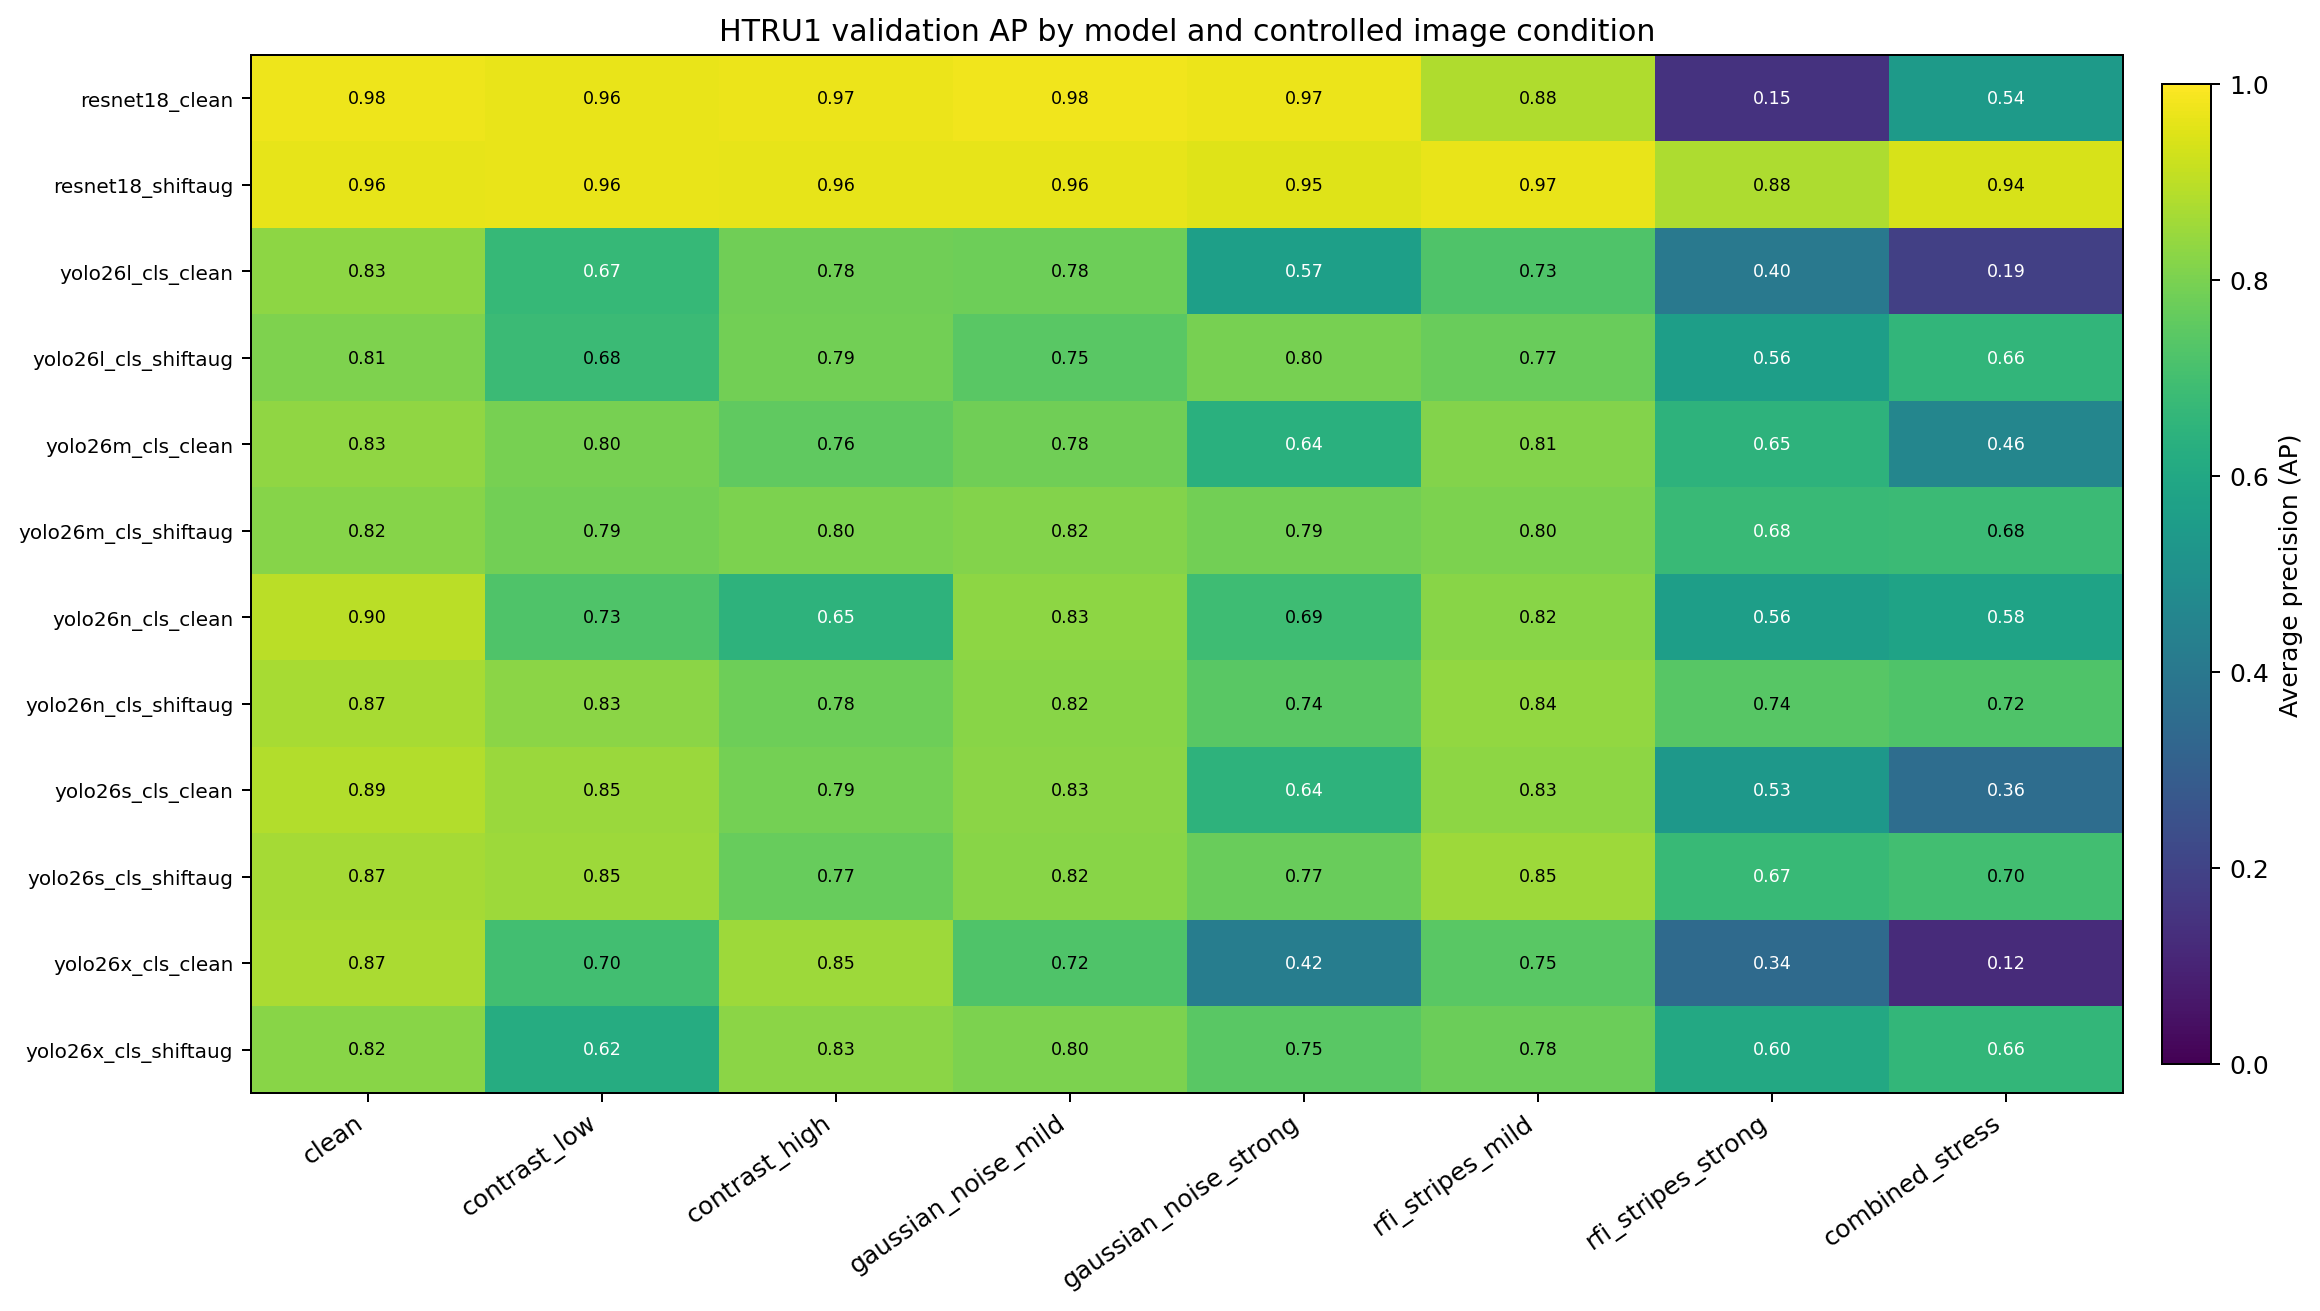

02_clean_vs_stress_AP.png


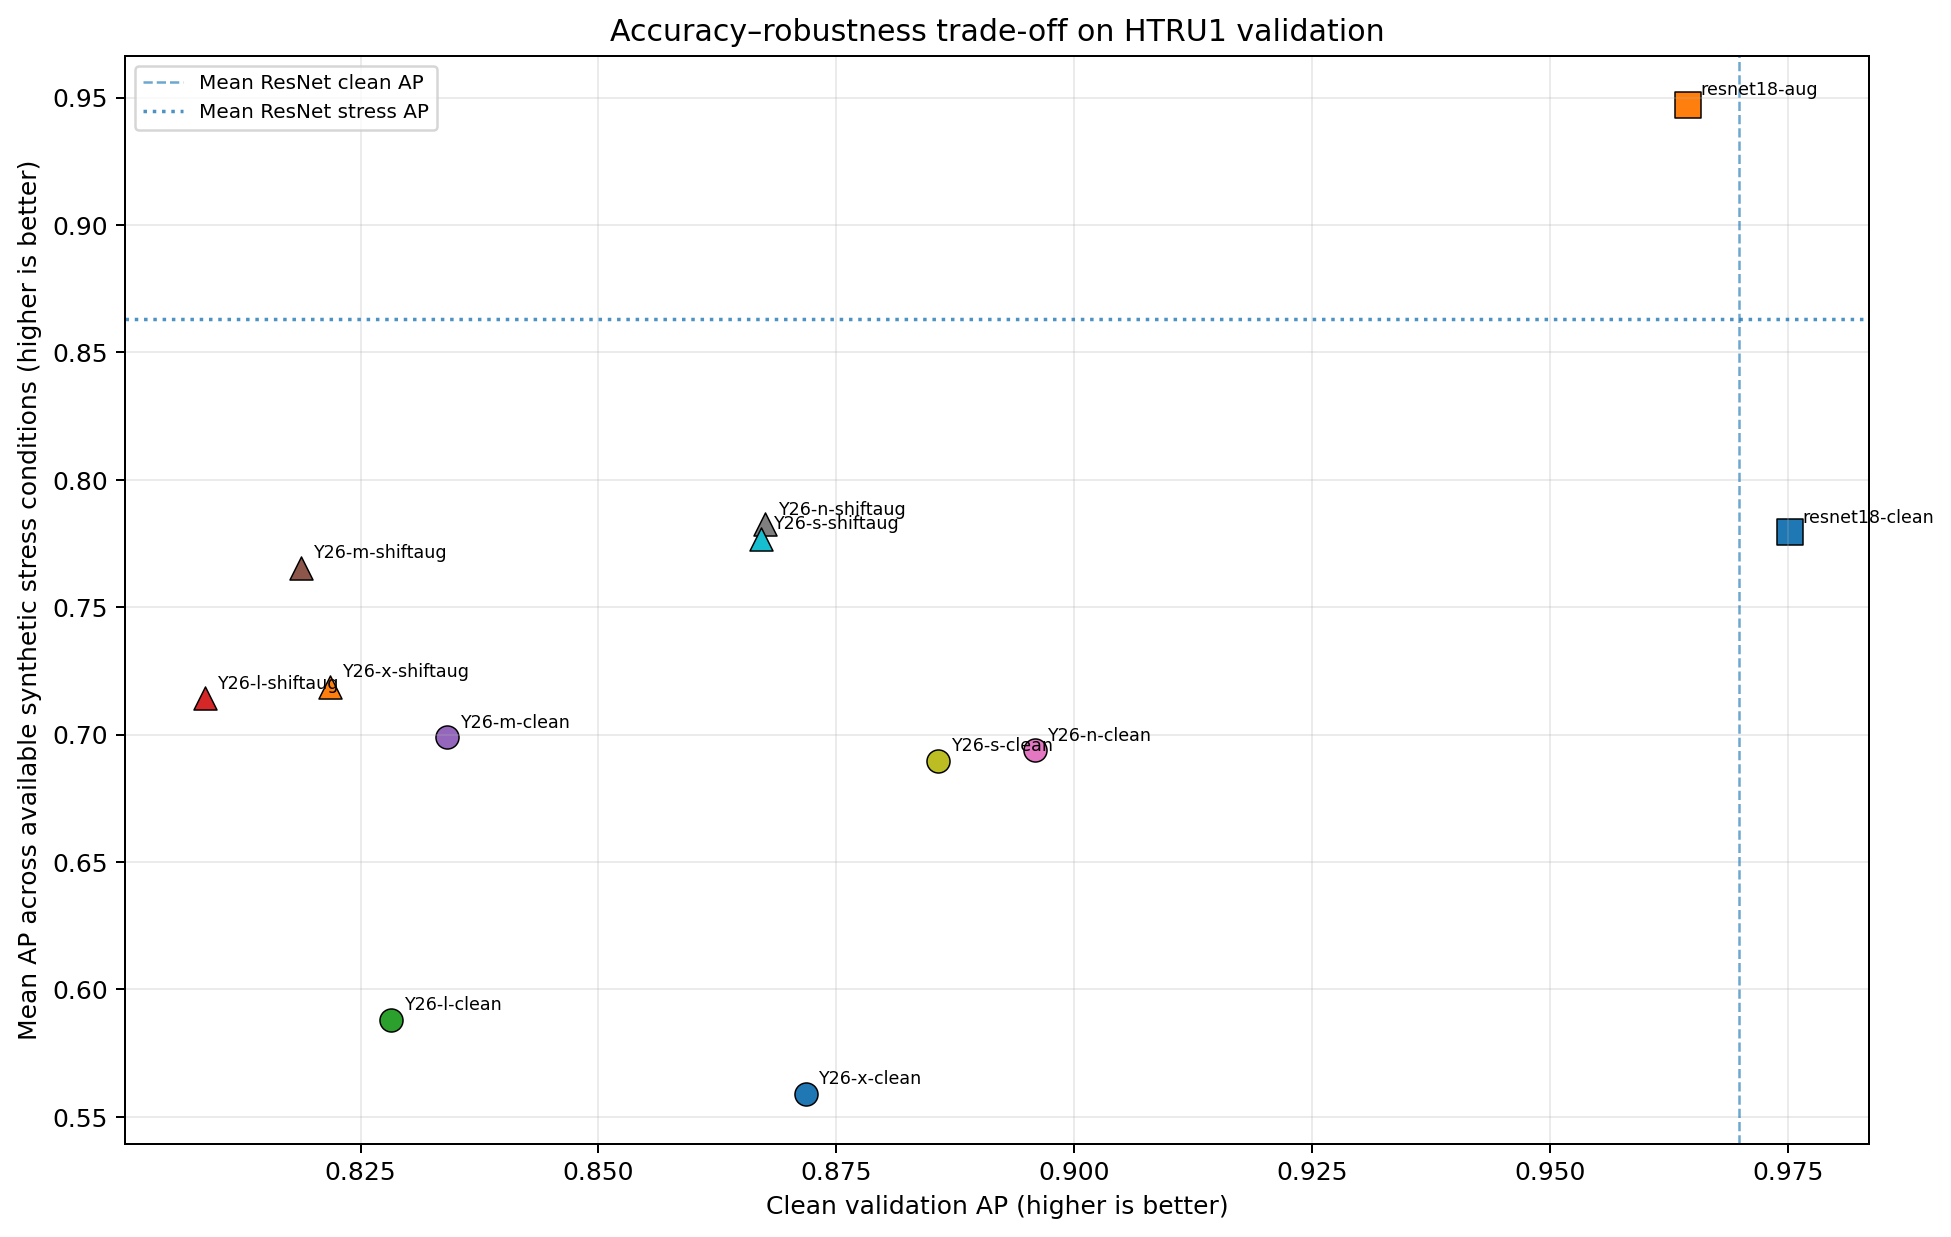

03_top100_candidate_review.png


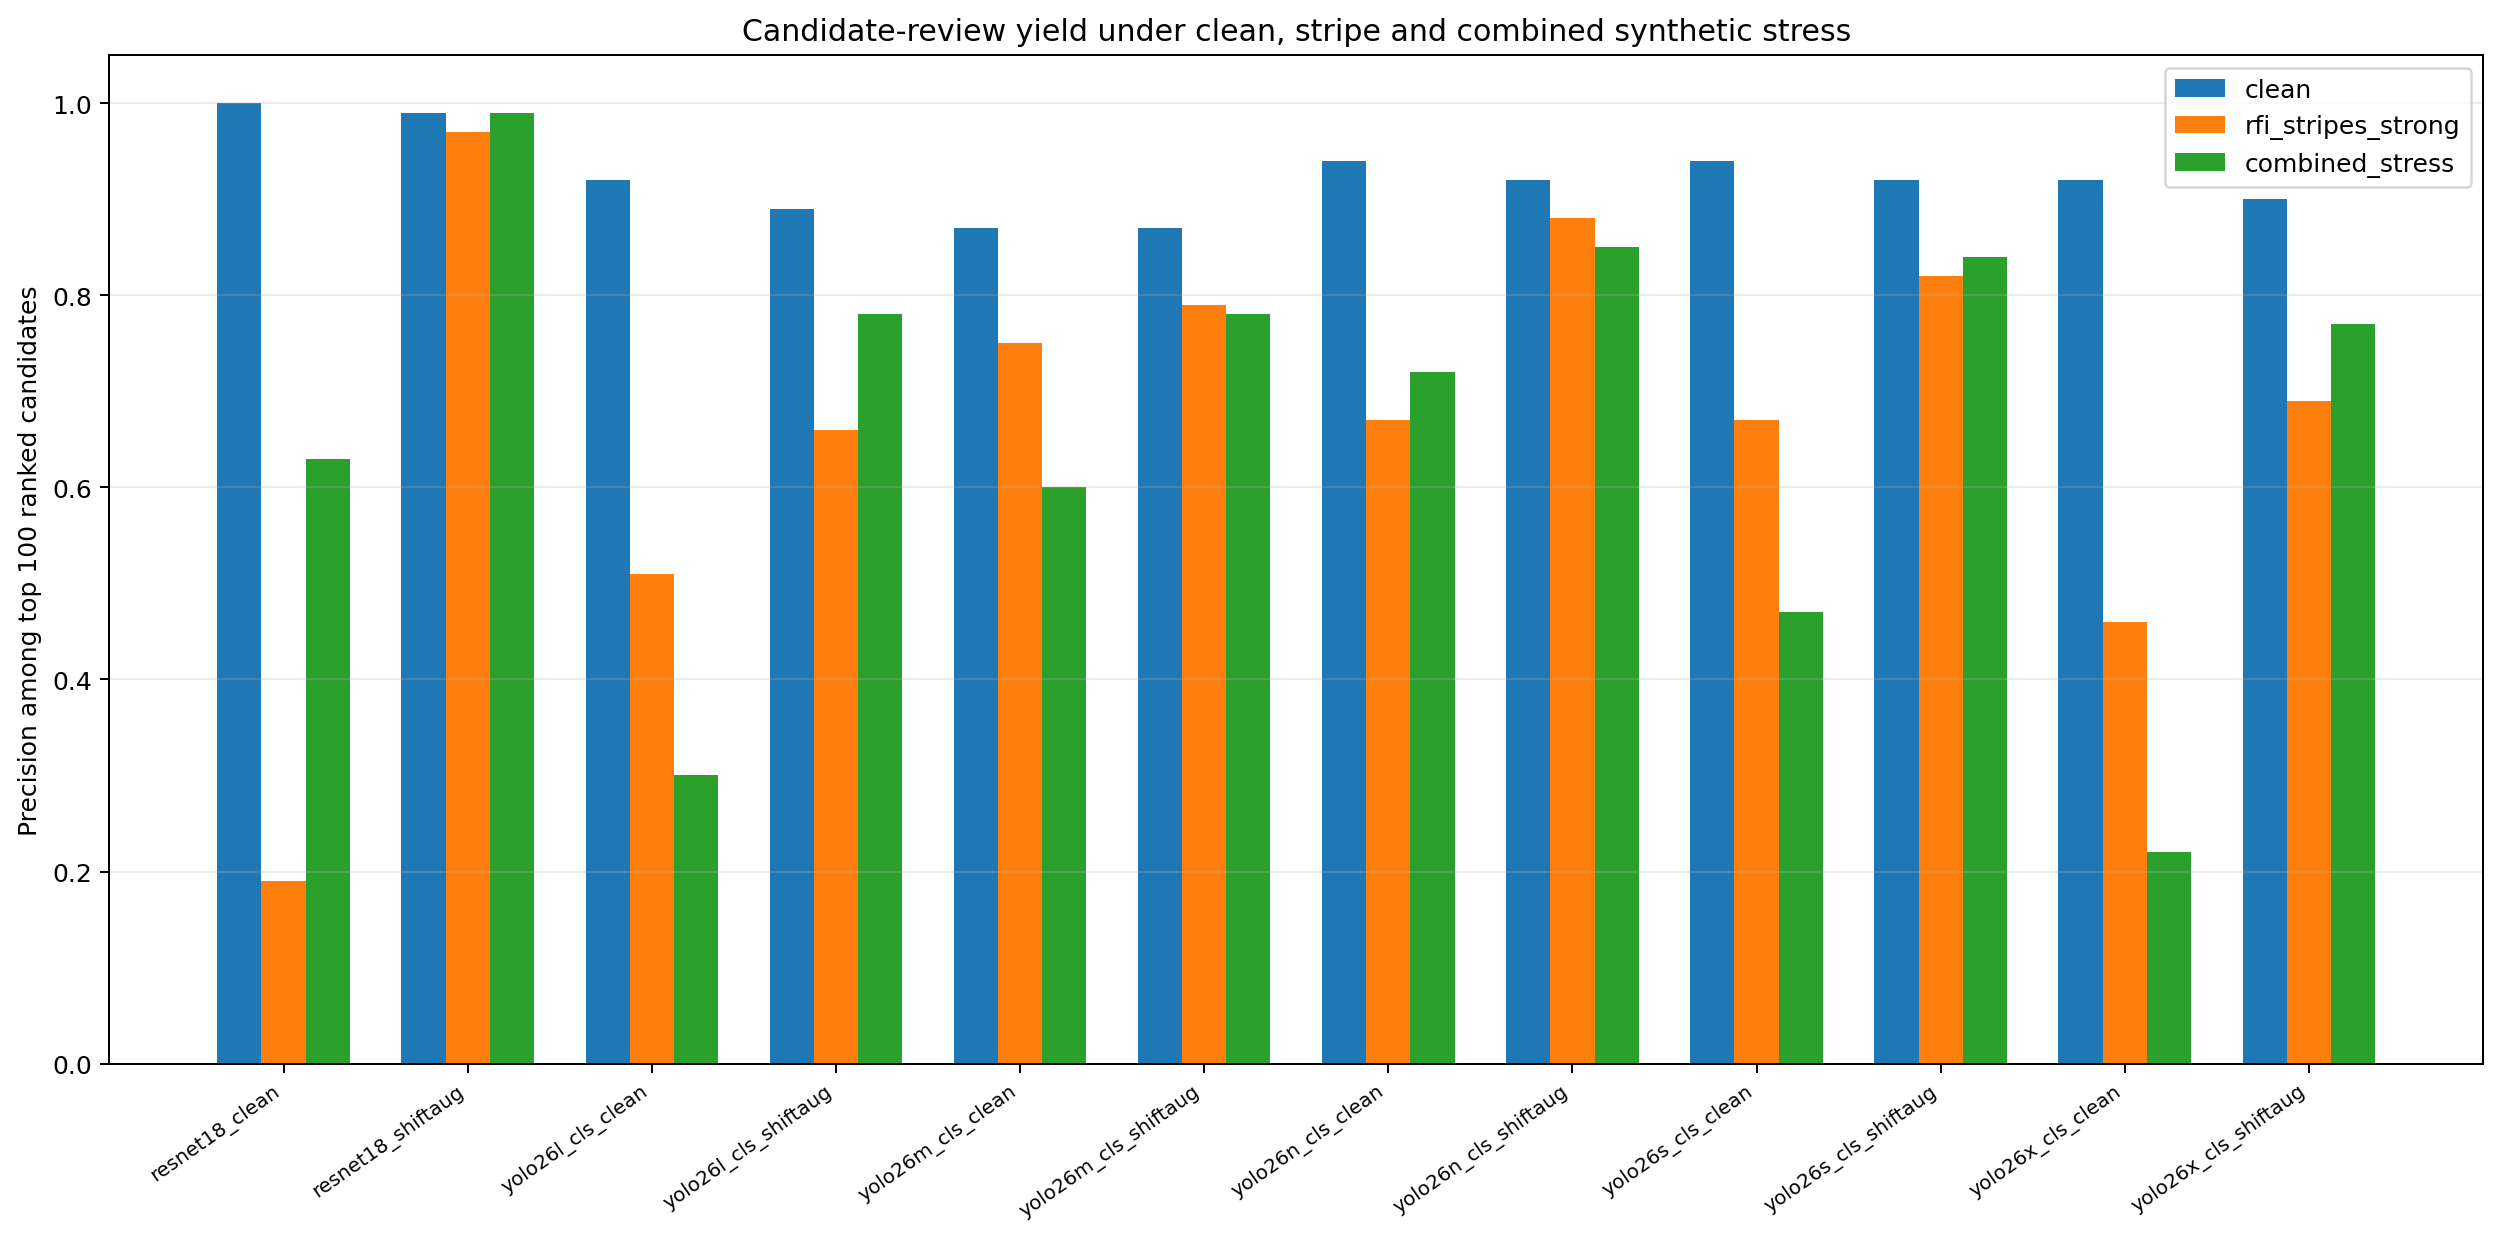

04_stress_AP_vs_throughput.png


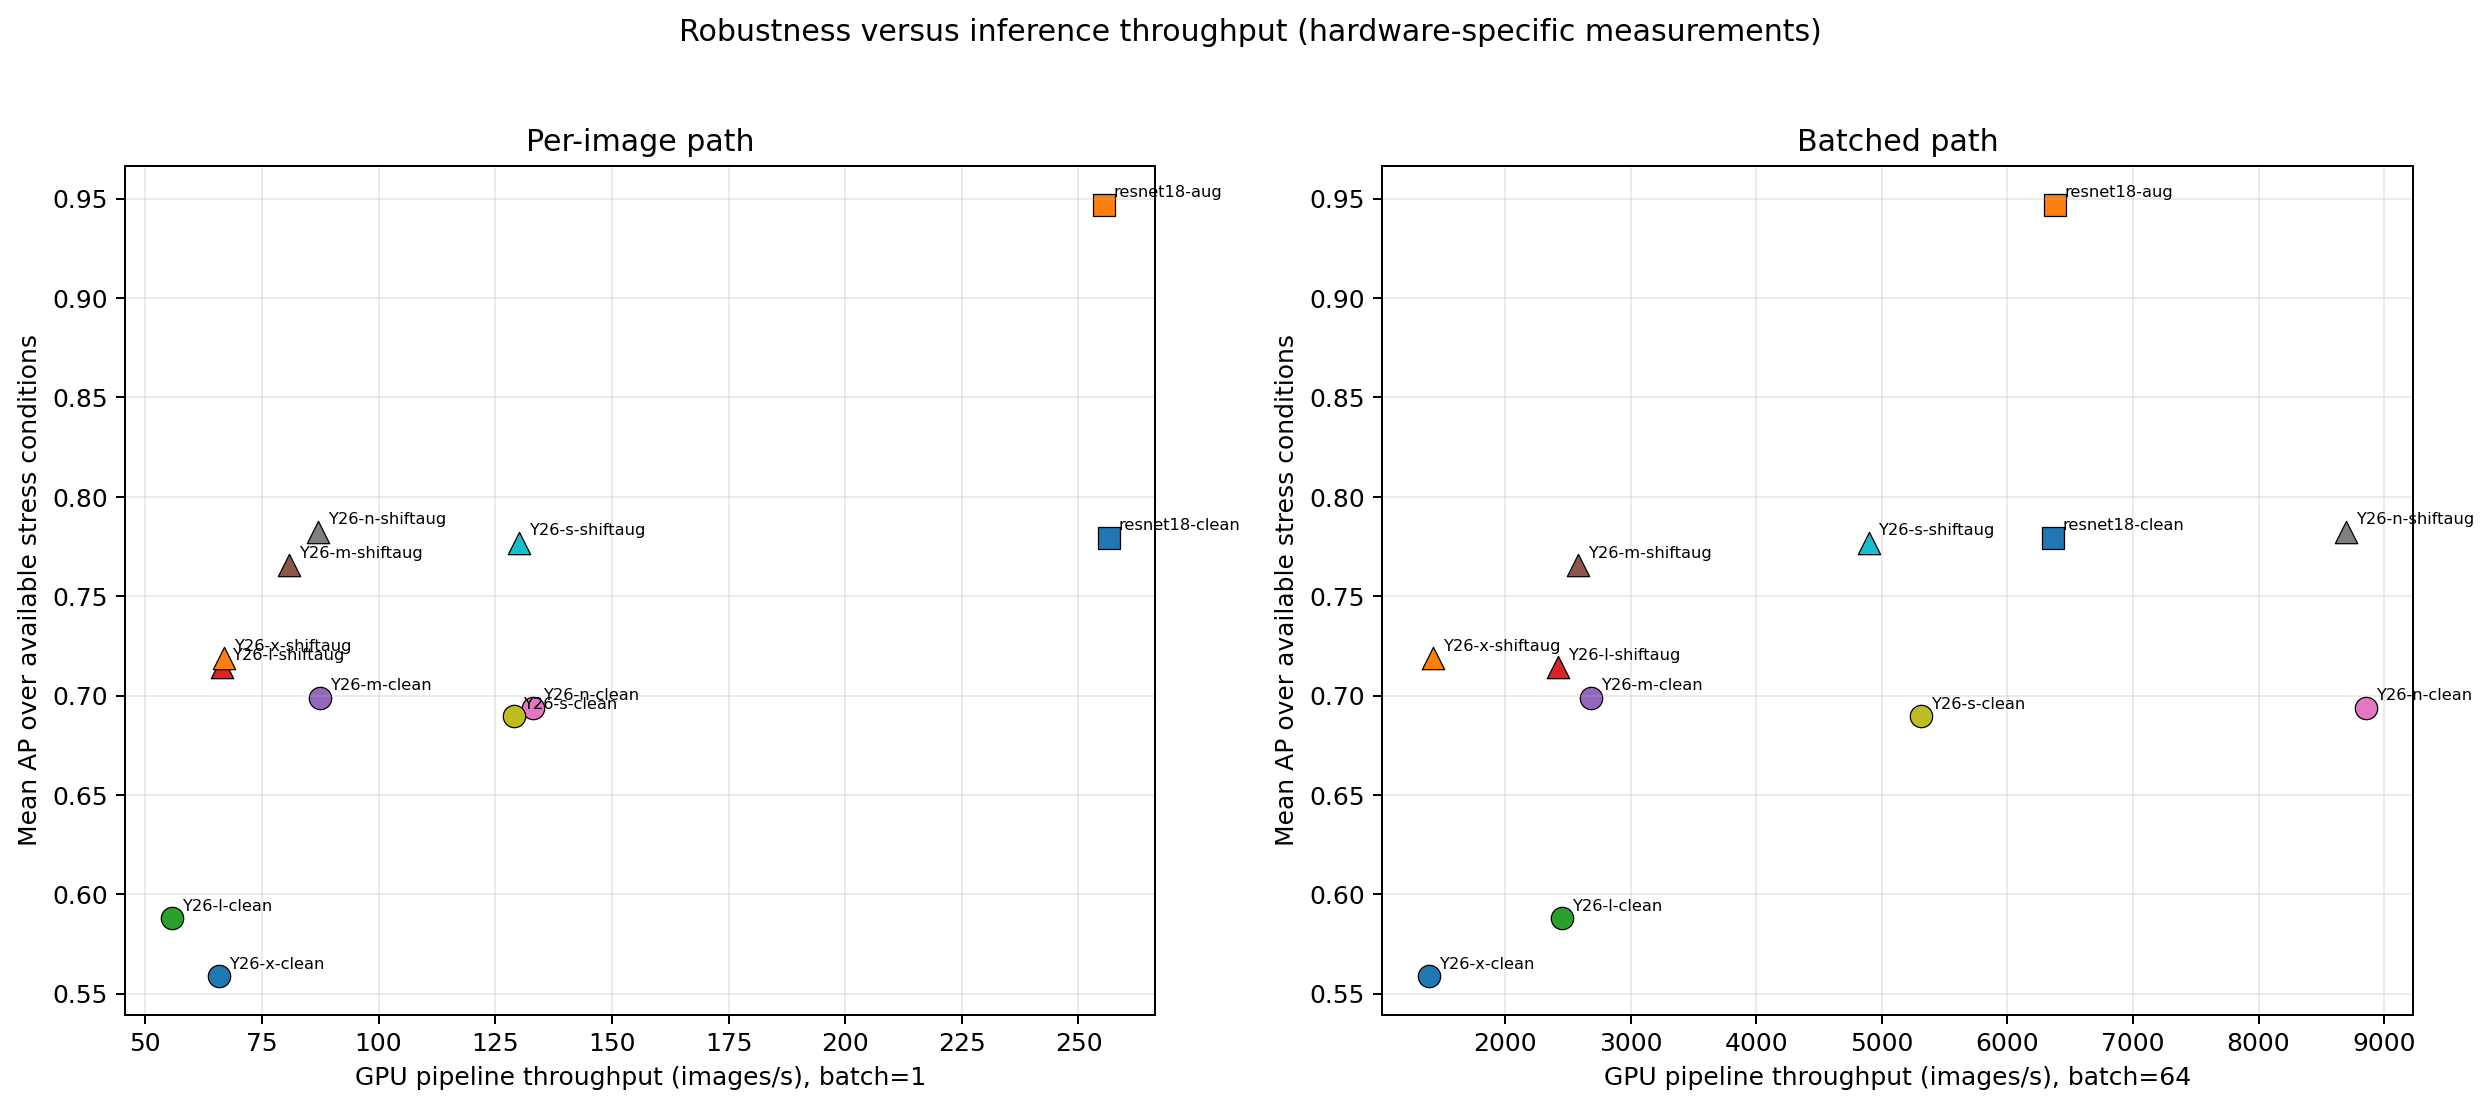


Download plot bundle with:
from google.colab import files; files.download('/content/yolo26_communication_plots/communication_graphs_bundle.zip')


In [ ]:
# HTRU1 YOLO26 — COMMUNICATION PLOTS ONLY
# Run after the current YOLO26 sweep has written at least some CSV metrics.
# It does NOT train models and writes plots/bundles to local Colab storage, not Drive.

import os, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPyImage
from google.colab import drive

drive.mount('/content/drive')

# Search the previous Drive output location first, then the local-first updated notebook.
REPORT_CANDIDATES = [
    Path('/content/drive/MyDrive/Pulsar_Experiment_B_YOLO26_FinalSweep/reports'),
    Path('/content/drive/MyDrive/Pulsar_Experiment_B_Robustness/reports'),
    Path('/content/yolo26_final_sweep_work/project/reports'),
    Path('/content/yolo26_final_sweep_work/reports'),
]
REPORT_SOURCE = next((p for p in REPORT_CANDIDATES if
                      (p / 'robustness_metrics.csv').exists() or
                      (p / 'robustness_progress.csv').exists()), None)
if REPORT_SOURCE is None:
    raise FileNotFoundError(
        'No robustness CSV found yet. Wait for Phase B to write robustness_progress.csv, '
        'then rerun this plotting cell. If Drive quota prevented all writes, free space first '
        'or use the local-first full notebook.'
    )

ROBUST_PATH = next((p for p in [REPORT_SOURCE / 'robustness_metrics.csv',
                                REPORT_SOURCE / 'robustness_progress.csv'] if p.exists()), None)
SPEED_PATH = next((p for p in [REPORT_SOURCE / 'inference_throughput.csv',
                              REPORT_SOURCE / 'throughput_progress.csv'] if p.exists()), None)
OUT_DIR = Path('/content/yolo26_communication_plots')
OUT_DIR.mkdir(parents=True, exist_ok=True)

robust = pd.read_csv(ROBUST_PATH)
required = {'model', 'condition', 'AP'}
if not required.issubset(robust.columns):
    raise ValueError(f'Unexpected robustness columns in {ROBUST_PATH}: {list(robust.columns)}')
robust = robust.drop_duplicates(subset=['model', 'condition'], keep='last')
robust['model'] = robust['model'].astype(str)
robust['condition'] = robust['condition'].astype(str)

speed = pd.DataFrame()
if SPEED_PATH is not None:
    speed = pd.read_csv(SPEED_PATH)
    expected_speed_cols = {'model', 'device', 'batch_size', 'pipeline_images_per_second'}
    if not expected_speed_cols.issubset(speed.columns):
        warnings.warn(f'Throughput file columns do not match expected schema: {list(speed.columns)}. Speed plots skipped.')
        speed = pd.DataFrame()
    else:
        speed = speed.drop_duplicates(subset=['model', 'device', 'batch_size'], keep='last')

conditions_order = [
    'clean', 'contrast_low', 'contrast_high', 'gaussian_noise_mild',
    'gaussian_noise_strong', 'rfi_stripes_mild', 'rfi_stripes_strong', 'combined_stress'
]
model_order = sorted(robust['model'].unique(), key=lambda x: (0 if x.startswith('resnet') else 1, x))
heat = robust.pivot_table(index='model', columns='condition', values='AP', aggfunc='mean')
heat = heat.reindex(index=model_order, columns=[c for c in conditions_order if c in heat.columns])

# GRAPH 1 — AP heatmap: best overview of which image shifts hurt each model.
fig_h = max(5.5, 0.45 * len(heat.index) + 2)
fig, ax = plt.subplots(figsize=(13, fig_h))
im = ax.imshow(heat.values.astype(float), aspect='auto', vmin=0, vmax=1, cmap='viridis')
ax.set_xticks(np.arange(len(heat.columns)))
ax.set_xticklabels(list(heat.columns), rotation=35, ha='right')
ax.set_yticks(np.arange(len(heat.index)))
ax.set_yticklabels(list(heat.index), fontsize=8)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        value = heat.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if value < 0.68 else 'black')
ax.set_title('HTRU1 validation AP by model and controlled image condition')
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, label='Average precision (AP)')
fig.tight_layout()
heat_path = OUT_DIR / '01_AP_robustness_heatmap.png'
fig.savefig(heat_path, dpi=180, bbox_inches='tight'); plt.close(fig)

# Summary derived directly from the robustness metric table.
wide = robust.pivot_table(index='model', columns='condition', values='AP', aggfunc='mean')
if 'clean' not in wide.columns:
    raise ValueError('No clean-condition AP scores are present yet. Rerun after at least one clean evaluation.')
stress_conditions = [c for c in conditions_order if c != 'clean' and c in wide.columns]
summary_rows = []
for model in wide.index:
    stress_vals = wide.loc[model, stress_conditions].dropna() if stress_conditions else pd.Series(dtype=float)
    cond_vals = wide.loc[model].drop(labels=['clean'], errors='ignore').dropna()
    worst = cond_vals.idxmin() if len(cond_vals) else 'not available'
    summary_rows.append({
        'model': model,
        'clean_AP': float(wide.loc[model, 'clean']) if pd.notna(wide.loc[model, 'clean']) else np.nan,
        'mean_AP_available_stress_conditions': float(stress_vals.mean()) if len(stress_vals) else np.nan,
        'number_of_stress_conditions_available': int(len(stress_vals)),
        'worst_available_stress_condition': worst,
        'worst_available_stress_AP': float(cond_vals.min()) if len(cond_vals) else np.nan,
    })
summary = pd.DataFrame(summary_rows)

# GRAPH 2 — clean AP vs mean stress AP: conveys the accuracy–robustness objective.
fig, ax = plt.subplots(figsize=(11, 7))
for row in summary.itertuples():
    if pd.isna(row.clean_AP) or pd.isna(row.mean_AP_available_stress_conditions):
        continue
    is_resnet = str(row.model).startswith('resnet')
    is_aug = str(row.model).endswith('shiftaug')
    marker = 's' if is_resnet else ('^' if is_aug else 'o')
    ax.scatter(row.clean_AP, row.mean_AP_available_stress_conditions,
               s=110 if is_resnet else 85, marker=marker, edgecolors='black', linewidths=0.6)
    short = str(row.model).replace('yolo26', 'Y26-').replace('_cls_', '-').replace('_shiftaug', '-aug').replace('_clean', '-clean')
    ax.annotate(short, (row.clean_AP, row.mean_AP_available_stress_conditions), xytext=(5, 4),
                textcoords='offset points', fontsize=7)
res = summary[summary['model'].str.startswith('resnet')]
if len(res):
    ax.axvline(res['clean_AP'].mean(), linestyle='--', linewidth=1, alpha=0.65, label='Mean ResNet clean AP')
    ax.axhline(res['mean_AP_available_stress_conditions'].mean(), linestyle=':', linewidth=1.4, alpha=0.8,
               label='Mean ResNet stress AP')
ax.set_xlabel('Clean validation AP (higher is better)')
ax.set_ylabel('Mean AP across available synthetic stress conditions (higher is better)')
ax.set_title('Accuracy–robustness trade-off on HTRU1 validation')
ax.grid(True, alpha=0.25); ax.legend(fontsize=8)
fig.tight_layout()
trade_path = OUT_DIR / '02_clean_vs_stress_AP.png'
fig.savefig(trade_path, dpi=180, bbox_inches='tight'); plt.close(fig)

# GRAPH 3 — top-100 precision. This communicates the likely review yield for a human triaging candidates.
if 'precision_at_top_k' in robust.columns:
    review_conditions = ['clean', 'rfi_stripes_strong', 'combined_stress']
    review = robust[robust['condition'].isin(review_conditions)]
    review = review.pivot_table(index='model', columns='condition', values='precision_at_top_k', aggfunc='mean')
    review = review.reindex([m for m in model_order if m in review.index])
    fig, ax = plt.subplots(figsize=(14, 7))
    x = np.arange(len(review.index)); width = 0.24
    for j, condition in enumerate(review_conditions):
        if condition in review.columns:
            ax.bar(x + (j - 1) * width, review[condition].values, width, label=condition)
    ax.set_xticks(x); ax.set_xticklabels(list(review.index), rotation=35, ha='right', fontsize=8)
    ax.set_ylim(0, 1.05); ax.set_ylabel('Precision among top 100 ranked candidates')
    ax.set_title('Candidate-review yield under clean, stripe and combined synthetic stress')
    ax.grid(axis='y', alpha=0.25); ax.legend()
    fig.tight_layout()
    review_path = OUT_DIR / '03_top100_candidate_review.png'
    fig.savefig(review_path, dpi=180, bbox_inches='tight'); plt.close(fig)
else:
    review_path = None

# GRAPH 4 — measured throughput vs mean stress AP for batch=1 and batch=64.
throughput_path = None
if not speed.empty:
    gpu = speed[speed['device'].astype(str).str.contains('cuda|gpu', case=False, regex=True)].copy()
    if not gpu.empty:
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        for ax, batch_size in zip(axes, [1, 64]):
            s = gpu[gpu['batch_size'].astype(int) == batch_size]
            joined = summary.merge(s[['model', 'pipeline_images_per_second']], on='model', how='inner')
            for row in joined.itertuples():
                if pd.isna(row.mean_AP_available_stress_conditions):
                    continue
                is_resnet = str(row.model).startswith('resnet')
                is_aug = str(row.model).endswith('shiftaug')
                marker = 's' if is_resnet else ('^' if is_aug else 'o')
                ax.scatter(row.pipeline_images_per_second, row.mean_AP_available_stress_conditions,
                           s=80, marker=marker, edgecolors='black', linewidths=0.5)
                short = str(row.model).replace('yolo26', 'Y26-').replace('_cls_', '-').replace('_shiftaug', '-aug').replace('_clean', '-clean')
                ax.annotate(short, (row.pipeline_images_per_second, row.mean_AP_available_stress_conditions),
                            xytext=(4, 3), textcoords='offset points', fontsize=6.5)
            ax.set_xlabel(f'GPU pipeline throughput (images/s), batch={batch_size}')
            ax.set_ylabel('Mean AP over available stress conditions')
            ax.set_title('Per-image path' if batch_size == 1 else 'Batched path')
            ax.grid(True, alpha=0.25)
        fig.suptitle('Robustness versus inference throughput (hardware-specific measurements)', y=1.02)
        fig.tight_layout()
        throughput_path = OUT_DIR / '04_stress_AP_vs_throughput.png'
        fig.savefig(throughput_path, dpi=180, bbox_inches='tight'); plt.close(fig)

summary_path = OUT_DIR / 'derived_model_summary.csv'
summary.to_csv(summary_path, index=False)
# Preserve the source tables with the graphs, so figures can be traced back to metrics.
robust.to_csv(OUT_DIR / 'source_robustness_metrics.csv', index=False)
if not speed.empty:
    speed.to_csv(OUT_DIR / 'source_inference_throughput.csv', index=False)

conditions_per_model = robust.groupby('model')['condition'].nunique()
complete_models = int((conditions_per_model >= 8).sum())
expected_models = 12
status = 'complete' if complete_models == expected_models else 'partial or still running'
report = OUT_DIR / 'GRAPH_GUIDE.md'
report.write_text(
    '# HTRU1 YOLO26 communication plots\n\n'
    f'- Source metrics directory: `{REPORT_SOURCE}`\n'
    f'- Robustness data source: `{ROBUST_PATH.name}`\n'
    f'- Throughput data source: `{SPEED_PATH.name if SPEED_PATH else "not found yet"}`\n'
    f'- Detected status: **{status}** ({complete_models} models currently have all 8 conditions; expected 12).\n\n'
    '## How to communicate the result\n\n'
    '1. Start with `02_clean_vs_stress_AP.png`: models nearer the upper-right have stronger clean AP and mean AP under tested synthetic shifts.\n'
    '2. Use `01_AP_robustness_heatmap.png` to show which perturbations degrade each model.\n'
    '3. Use `03_top100_candidate_review.png` to explain candidate-review yield; precision@100 is not recall of all pulsars.\n'
    '4. Use `04_stress_AP_vs_throughput.png` to discuss accuracy/robustness versus measured inference throughput when this plot is available.\n\n'
    'Caveat: synthetic contrast/noise/stripe conditions are image-space engineering proxies, not calibrated real telescope RFI. These are validation results, not untouched official-test performance. Throughput is specific to the runtime/GPU and excludes PFD parsing and telescope data ingress.\n',
    encoding='utf-8'
)

files_to_zip = [p for p in OUT_DIR.iterdir() if p.is_file() and p.suffix.lower() in {'.png','.csv','.md'}]
zip_path = OUT_DIR / 'communication_graphs_bundle.zip'
with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for path in files_to_zip:
        if path != zip_path:
            zf.write(path, arcname=path.name)

print('Metrics read from:', ROBUST_PATH)
print('Plots and report saved locally to:', OUT_DIR)
print('Run status:', status)
display(summary.sort_values('mean_AP_available_stress_conditions', ascending=False))
for path in [heat_path, trade_path, review_path, throughput_path]:
    if path is not None and path.exists():
        print(path.name)
        display(IPyImage(filename=str(path)))
print('\nDownload plot bundle with:')
print("from google.colab import files; files.download('/content/yolo26_communication_plots/communication_graphs_bundle.zip')")
